# Sparkov vs IEEE-CIS Results Comparison

## 1. Introduction

The M0 to M2 results differ between Sparkov (`05_sparkov_m0_m2.ipynb`) and IEEE-CIS (`05_ieee_m0_m2.ipynb`, `05b_ieee_lightgbm_m0_m1.ipynb` and `05c_ieee_lightgbm_m2.ipynb`). This suggests that findings from one dataset may not necessarily apply to the other. For example, adding class weights improves LightGBM's PR-AUC by 0.053 on Sparkov but reduces PR-AUC across all four model families on IEEE-CIS.

In this notebook, we compare the results across both datasets and conduct additional exploratory data analysis (EDA) to better understand the differences.

Only the training and validation rows are used for the analysis, while the test rows are reserved for the final evaluation.

### 1.1 Results Side by Side

The table below summarises the validation PR-AUC results, which is our main evaluation metric. Each model family uses the same settings across both datasets, with a fixed random seed of 100. M1 adds balanced class weights to M0, M2 introduces scheduled retraining with a 7-day label delay, M3 adds pseudo-labels for the transactions within this delay and M4 adds an anomaly score as a feature.

| | Sparkov | IEEE-CIS |
|---|---|---|
| Validation fraud rate | 0.59% | 3.92% |
| M0 CatBoost / LightGBM / RF / LR | 0.987 / 0.933 / 0.959 / 0.794 | 0.626 / 0.595 / 0.559 / 0.527 |
| M1 CatBoost / LightGBM / RF / LR | 0.989 / 0.986 / 0.961 / 0.658 | 0.591 / 0.568 / 0.556 / 0.504 |
| M1 - M0: CatBoost / LightGBM / RF / LR | +0.002 / +0.053 / +0.001 / -0.136 | -0.035 / -0.027 / -0.003 / -0.022 |
| M0 without card history: CatBoost / RF / LR | -0.062 / -0.071 / -0.329 | -0.010 / -0.004 / +0.001 |
| M2 CatBoost / LightGBM / RF / LR | 0.988 / 0.985 / 0.947 / 0.815 | 0.653 / 0.619 / 0.562 / 0.511 |
| M2 - static: CatBoost / LightGBM / RF / LR | +0.001 / 0.000 / +0.002 / +0.002 | +0.053 / +0.047 / +0.017 / +0.010 |
| M3 - base model | +0.0011 (M1 CatBoost with the 7-day delay, 1 seed) | -0.008 with seed 100, +0.0005 over 3 seeds (M2 CatBoost after tuning) |
| M4 - base model | -0.0027 (M1 CatBoost) | -0.004 (M2 CatBoost after tuning) |
| Best model after M2 | M1 CatBoost (0.989), with M2 CatBoost at 0.988 | M2 CatBoost (0.653, improving to 0.667 after tuning in notebook 06_ieee) |

The remaining sections cover the following comparisons:

- **Dataset properties (Section 3):** Compare the fraud rates, card-level transaction distributions and categorical features of both datasets to provide context for the later analyses.

- **M0 performance (Section 4):** Examine why the best M0 model achieves a PR-AUC of 0.987 on Sparkov but only 0.626 on IEEE-CIS.

- **M0 LR vs tree-based models (Section 5):** Investigate why LR performs much worse than the tree-based models on Sparkov, while the performance gap is smaller on IEEE-CIS.

- **Model family rankings (Section 6):** Compare the rankings across M0, M1 and M2, where CatBoost generally performs best and LR performs worst on both datasets.

- **M1 class weights (Section 7):** Examine why class weights have a similar effect on precision and recall at the 0.5 threshold in both datasets, but affect PR-AUC differently, particularly for LightGBM.

- **M0 card-history features (Section 8):** Investigate why card-history features provide substantial improvements on Sparkov but have little effect on IEEE-CIS.

- **M2 retraining (Section 9):** Examine why scheduled retraining improves performance on IEEE-CIS but provides little benefit on Sparkov.

- **M2 history window and retraining frequency (Section 10):** Compare the effects of different training history windows and retraining frequencies, including why shorter windows lead to much larger performance drops on Sparkov.

- **M3 pseudo-labelling (Section 11):** Examine why pseudo-labelling the transactions within the label delay gives almost no improvement on either dataset.

- **M4 anomaly score (Section 12):** Examine why adding an anomaly score as a feature does not improve either dataset.

Each section begins by comparing the results from the earlier model notebooks, followed by possible explanations for the observed differences. Where appropriate, we conduct additional experiments within the same section to investigate these explanations.

## 2. Data Loading
We load both processed datasets from notebook 04 and keep the training and validation rows. For each row we keep the day (days since the first transaction), the label and the card:
- **Sparkov**: the 62 model features, the timestamp and the card number

- **IEEE-CIS**: the 575 candidate features that the M0 to M2 models use in notebook 05_ieee (not the 115 features selected in notebook 06_ieee, which are only for the tuned M2 CatBoost). They are prepared in the same way as in notebook 05_ieee: numeric columns as float32 and categorical columns as categories, including the 6 code columns (`card1`, `card2`, `card3`, `card5`, `addr1` and `addr2`). The card is the reconstructed card ID from notebook 03

In [1]:
import gc
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", 100)

PROCESSED_DIR = Path("../data/processed")
LABEL_DELAY_DAYS = 7
SEED = 100   # same seed as the model notebooks
# IEEE-CIS validation scores of the static and M2 runs from notebook 05_ieee
IEEE_M2_SCORES_DIR = Path("../results/ieee/m2_scores_refit")
# the slow runs are saved here
# a rerun loads them instead of training again
RUNS_DIR = Path("../results/comparison_runs")
RUNS_DIR.mkdir(parents=True, exist_ok=True)


def load_run(name):
    path = RUNS_DIR / f"{name}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    return None


def save_run(name, result):
    pd.to_pickle(result, RUNS_DIR / f"{name}.pkl")

In [2]:
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

# Sparkov: 62 model features, label, day and card number
sparkov = pd.read_pickle(PROCESSED_DIR / "sparkov_features.pkl")
sparkov = sparkov[sparkov["sparkov_split"].isin(["train", "validation"])]
sparkov_feature_cols = feature_lists["sparkov_feature_cols"]
sparkov_cat_cols = feature_lists["sparkov_categorical_cols"]
sparkov_num_cols = []
for col in sparkov_feature_cols:
    if col not in sparkov_cat_cols:
        sparkov_num_cols.append(col)
sparkov = sparkov[sparkov_feature_cols + ["is_fraud", "sparkov_split", "trans_date_trans_time", "cc_num"]].copy()
timestamp = pd.to_datetime(sparkov["trans_date_trans_time"])
sparkov["day"] = (timestamp - timestamp.min()).dt.days
sparkov["label"] = sparkov["is_fraud"].astype(int)
sparkov["split"] = sparkov["sparkov_split"]
sparkov["card"] = sparkov["cc_num"]
sparkov = sparkov.drop(columns=["trans_date_trans_time", "is_fraud", "sparkov_split", "cc_num"])

# IEEE-CIS: all 575 model features, prepared as in notebook 05_ieee
# numeric columns are float32 and categorical columns are categories
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
ieee_feature_cols = feature_lists["ieee_feature_cols"]
ieee_cat_cols = []
ieee_num_cols = []
for col in ieee_feature_cols:
    if col in feature_lists["ieee_categorical_cols"] or col in CODE_AS_CATEGORY:
        ieee_cat_cols.append(col)
    else:
        ieee_num_cols.append(col)
ieee_keep = ieee_feature_cols + ["isFraud", "ieee_split", "TransactionDT", "card_id"]
for col in ["TransactionAmt", "C1", "C13", "D1"]:
    if col not in ieee_keep:
        ieee_keep.append(col)
ieee = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
ieee = ieee.loc[ieee["ieee_split"].isin(["train", "validation"]), ieee_keep].copy()
ieee[ieee_num_cols] = ieee[ieee_num_cols].astype("float32")
for col in ieee_cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers become text codes e.g. 315.0 becomes "315"
        # missing values become "missing"
        numbers = pd.to_numeric(ieee[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(ieee), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole
        text[other] = numbers.to_numpy(dtype=object)[other]
        ieee[col] = pd.Series(text, index=ieee.index).astype("category")
    else:
        ieee[col] = ieee[col].astype("object").fillna("missing").astype(str).astype("category")
ieee["time"] = ieee["TransactionDT"]
ieee["day"] = ieee["TransactionDT"] // 86400
ieee["day"] = ieee["day"] - ieee["day"].min()
ieee["label"] = ieee["isFraud"].astype(int)
ieee["split"] = ieee["ieee_split"]
ieee["card"] = ieee["card_id"]
ieee = ieee.drop(columns=["TransactionDT", "isFraud", "ieee_split", "card_id"])

# the 575 features go into their own frame
# `ieee` keeps the other columns and the few features used in Sections 3 and 5
ieee_X = ieee[ieee_feature_cols]
ieee_other_cols = ["time", "day", "label", "split", "card", "TransactionAmt", "C1", "C13", "D1"]
for col in ieee_cat_cols:
    ieee_other_cols.append(col)
ieee = ieee[ieee_other_cols].copy()
gc.collect()
# the training rows come first, so each split is one block of rows
IEEE_N_TRAIN = int((ieee["split"] == "train").sum())
assert (ieee["split"].iloc[:IEEE_N_TRAIN] == "train").all()

datasets = {"Sparkov": sparkov, "IEEE-CIS": ieee}
for name in datasets:
    df = datasets[name]
    train = df[df["split"] == "train"]
    val = df[df["split"] == "validation"]
    print(f"{name}: training rows {len(train):,} (days {train['day'].min()} to {train['day'].max()}, fraud {train['label'].mean():.2%}) | "
          f"validation rows {len(val):,} (fraud {val['label'].mean():.2%})")

/var/folders/dt/5cbk9kp92zggglf749y05y8c0000gn/T/ipykernel_20421/73240862.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ieee["time"] = ieee["TransactionDT"]
/var/folders/dt/5cbk9kp92zggglf749y05y8c0000gn/T/ipykernel_20421/73240862.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ieee["day"] = ieee["TransactionDT"] // 86400
/var/folders/dt/5cbk9kp92zggglf749y05y8c0000gn/T/ipykernel_20421/73240862.py:55: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

Sparkov: training rows 1,037,340 (days 0 to 430, fraud 0.58%) | validation rows 259,335 (fraud 0.59%)
IEEE-CIS: training rows 377,945 (days 0 to 108, fraud 3.41%) | validation rows 94,487 (fraud 3.92%)


## 3. Dataset Properties
The later sections keep coming back to a few basic properties of the 2 datasets, so we put them in one table first. The fraud rates are already in notebook 02 and 04b **BUT** we have not yet compared how many transactions and frauds each card has, or how large the categorical columns are. All values are from the training rows

In [3]:
# properties of the training rows of each dataset
properties = {}
for name in datasets:
    df = datasets[name]
    train = df[df["split"] == "train"]

    # one row per card with its number of transactions and frauds
    # IEEE-CIS rows without a card ID are left out
    cards = train.groupby("card")["label"].agg(["size", "sum"])
    fraud_cards = cards[cards["sum"] > 0]

    if name == "Sparkov":
        cat_cols = sparkov_cat_cols
        n_features = len(sparkov_feature_cols)
    else:
        cat_cols = ieee_cat_cols
        n_features = len(ieee_feature_cols)
    counts = []
    for col in cat_cols:
        counts.append(train[col].nunique())
    counts = pd.Series(counts, index=cat_cols).sort_values(ascending=False)

    fraud_rate = train["label"].mean()
    properties[name] = {
        "training rows": f"{len(train):,}",
        "days covered": f"{train['day'].max() - train['day'].min() + 1}",
        "fraud rate": f"{fraud_rate:.2%}",
        "non-fraud rows per fraud row": f"{(train['label'] == 0).sum() / train['label'].sum():.0f}",
        "1 / fraud rate": f"{1 / fraud_rate:.0f}",
        "cards": f"{len(cards):,}",
        "transactions per card (median)": f"{cards['size'].median():,.0f}",
        "cards with at least 1 fraud": f"{len(fraud_cards):,} ({len(fraud_cards) / len(cards):.1%})",
        "fraud transactions per fraud card (median)": f"{fraud_cards['sum'].median():.0f}",
        "model features": f"{n_features}",
        "categorical columns": f"{len(cat_cols)}",
        "categorical columns with over 100 values": f"{int((counts > 100).sum())}",
        "largest categorical column": f"{counts.index[0]} ({counts.iloc[0]:,} values)"
    }
display(pd.DataFrame(properties))

,Sparkov,IEEE-CIS
training rows,"1,037,340","377,945"
days covered,431,109
fraud rate,0.58%,3.41%
non-fraud rows per fraud row,173,28
1 / fraud rate,174,29
cards,964,"157,121"
transactions per card (median),"1,147",1
cards with at least 1 fraud,603 (62.6%),"5,353 (3.4%)"
fraud transactions per fraud card (median),10,1
model features,62,575


**Takeaway: Dataset Properties**

- **Fraud rates:** Sparkov has a considerably lower fraud rate than IEEE-CIS (0.58% vs 3.41%), with approximately 173 non-fraud transactions per fraud transaction, compared to 28 on IEEE-CIS. These ratios also determine the balanced class weights applied in M1 (Section 7).

- **Card-level transaction patterns:** The two datasets differ substantially in their card-level distributions:
  - **Sparkov:** There are 964 cards, with a median of 1,147 transactions per card. Approximately 62.6% of cards have at least one fraudulent transaction, with a median of 10 fraud transactions among these cards. This indicates that cards generally have long transaction histories, and fraud often occurs multiple times on the same card.
  - **IEEE-CIS:** There are 157,121 reconstructed cards, with a median of only one transaction per card. Only 3.4% of cards have fraud, with a median of one fraudulent transaction among these cards. This suggests that most cards have limited transaction histories, reducing the amount of historical information available for constructing card-history features (Sections 8 and 10).

- **Feature characteristics:** Sparkov contains 62 features and three categorical columns with relatively low cardinality, with `state` having the highest number of unique values (51). In comparison, IEEE-CIS contains 575 features and 47 categorical columns, of which 10 have more than 100 unique values. The highest-cardinality feature is `card1`, with 11,945 unique values. These differences may influence how the models handle categorical information and adapt to changing transaction patterns (Sections 6 and 9).

## 4. M0

We first compare the M0 models, which are trained once without class weights. CatBoost performs best on both datasets, achieving a validation PR-AUC of 0.987 on Sparkov compared to 0.626 on IEEE-CIS (ROC-AUC of 0.9997 vs 0.926).

Since the PR-AUC of a random classifier is equal to the fraud rate, we also compare the results relative to this baseline. CatBoost performs approximately 167 times better than random on Sparkov (0.987 / 0.0059), compared to 16 times on IEEE-CIS (0.626 / 0.0392). This suggests that the performance gap cannot be explained by the different fraud rates alone. In fact, Sparkov has a lower fraud rate, which would generally make fraud detection more challenging if we considered class imbalance alone.

Based on the findings from the earlier notebooks, we identified three possible explanations for this difference:

- **Fraud patterns are more distinct in Sparkov:** Fraudulent transactions in Sparkov tend to follow clearer patterns in the available features. For example, fraud amounts are concentrated around a few narrow peaks, with a median of 396.51 compared to 47.28 for non-fraud transactions. The fraud rate also increases from approximately 0.1% during the day to 2.9% at 22:00 and 23:00 (notebook 02, *Amount and Temporal patterns*). As Sparkov is a simulated dataset, these patterns may reflect how fraud was generated. In contrast, transaction amounts for fraud and non-fraud cases in IEEE-CIS are much closer, with medians of 75.00 and 68.50 respectively (notebook 02, *Transaction amount, relative time*). Individual features also provide stronger separation in Sparkov, where transaction amount alone achieves an AUC of 0.83. On IEEE-CIS, the strongest single columns are `D5` with an AUC of 0.25 (fraud has lower values, so it separates about as well as an AUC of 0.75) and the strongest `C` features with an AUC of 0.68 to 0.69 (notebook 02, *Feature checks for modelling*).

- **IEEE-CIS may have greater label uncertainty:** In Sparkov, the fraud label identifies the fraudulent transaction itself. For IEEE-CIS, fraud labels are based on chargeback information, and subsequent transactions associated with the same account, email or address may also be labelled as fraud (notebook 02, *Explore columns for card ID reconstruction*). Our earlier analysis found that 46.9% of transactions following a previous fraud on the same card were labelled as fraud, compared to 1.46% for transactions without a previous fraud (notebook 03 Section 8 and notebook 04b). Some of these transactions may otherwise resemble legitimate purchases, making fraud harder to distinguish using the available features. This could limit how well the models can separate the two classes.

- **IEEE-CIS shows greater changes in model performance over time:** In Sparkov, a model trained once maintains a ROC-AUC between 0.993 and 0.999. In comparison, IEEE-CIS performance declines from approximately 0.92 to 0.84 over 18 weeks (notebook 04c, Section 3). Since validation transactions occur after the training period, changes in transaction patterns may reduce how well the relationships learned during training generalise to the validation data. This is explored further in Section 9.

Overall, the high M0 PR-AUC of 0.987 on Sparkov suggests that the models can learn the fraud patterns generated by the simulator. However, this level of performance may not be achievable on real-world transactions, where fraud patterns are more complex and less distinct. The IEEE-CIS results therefore provide a more realistic reference for fraud detection performance.

## 5. M0 LR vs M0 Trees

The performance gap between Logistic Regression (LR) and the best M0 tree-based model (CatBoost) differs across the two datasets. On Sparkov, LR achieves a PR-AUC of 0.794, which is 0.194 lower than CatBoost (0.987). In comparison, the gap is smaller on IEEE-CIS, where LR achieves 0.527 compared to CatBoost's 0.626, a difference of 0.099. Since LR uses the same preprocessing steps on both datasets (median imputation, arcsinh transformation, standardisation and one-hot encoding), this difference may be explained by the underlying data patterns.

LR models predictions using a linear combination of features, which can limit its ability to capture two types of relationships:

- **Non-linear relationships within individual features:** Fraud risk may not increase consistently with a feature's value. For example, fraud rates could be low for small transaction amounts, increase for medium amounts, decrease again and then rise for large amounts. A single coefficient cannot directly capture this pattern.

- **Interactions between features:** Fraud risk may depend on a combination of features rather than their individual effects. For example, a large transaction amount may only be suspicious when it occurs at night. Standard LR cannot directly capture this interaction without additional features.

The earlier analysis in notebook 02 (*Amount and Temporal patterns*) suggests that Sparkov contains both types of relationships. In comparison, the SHAP results from notebook 05_ieee (Section 8) suggest that several important IEEE-CIS features have more consistent directional effects, where higher values of `TransactionAmt`, `C1` and `card1_previous_count` generally increase predicted fraud risk.

To investigate whether these differences contribute to the larger performance gap on Sparkov, we conduct two additional analyses:

- **Fraud rate by transaction amount:** We divide the training transactions into 10 approximately equal-sized groups based on transaction amount and calculate the fraud rate for each group. This allows us to examine whether fraud risk increases consistently with transaction amount or follows a more irregular pattern.

- **Comparison of three simple models:** We train three models using the same four selected features from each dataset and evaluate their PR-AUC on the validation data. Each model is designed to capture different types of relationships.

  | Model | Non-linear relationships within individual features | Interactions between features |
  |---|---|---|
  | LR (arcsinh transformation and standardisation, as in M0) | No | No |
  | LR with features divided into 10 bins and one-hot encoded | Yes, each bin has its own coefficient | No |
  | Decision tree (max depth 3, up to 8 leaf nodes) | Yes | Yes |

  The binned LR allows us to examine whether non-linear relationships within individual features explain the original LR's lower performance. If its PR-AUC approaches that of the decision tree, these relationships may account for much of the gap. However, if the tree still performs substantially better, interactions between features may also contribute to the difference.

  We use a shallow decision tree to keep the comparison relatively simple. Since RF, CatBoost and LightGBM are all tree-based models, this allows us to examine whether even a single small tree can outperform LR without relying on a larger ensemble.

  The four features are selected using the same approach for both datasets: transaction amount and the three additional features with the strongest individual ability to distinguish fraud from non-fraud transactions, based on their training AUC. The candidates include the raw features examined in notebook 02 (*Feature checks for modelling*), together with transaction hour.

In [4]:
AMOUNT_COL = {"Sparkov": "amt", "IEEE-CIS": "TransactionAmt"}

# raw columns checked in notebook 02 (Feature checks for modelling)
# the hour is added as well
CANDIDATE_COLS = {"Sparkov": ["seconds_since_card_txn", "customer_age", "city_pop", "card_merchant_distance_km", "trans_hour"],
                  "IEEE-CIS": ["dist1", "dist2", "card_id_seconds_since_previous", "hour"]}
for i in range(1, 15):
    CANDIDATE_COLS["IEEE-CIS"].append(f"C{i}")
for i in range(1, 16):
    CANDIDATE_COLS["IEEE-CIS"].append(f"D{i}")

# rule: the amount and the 3 columns that separate fraud best on their own
# each column is scored by its AUC alone on the training rows
# 0.5 means no separation, so the strength is the distance from 0.5
RULE_COLS = {}
for name in ["Sparkov", "IEEE-CIS"]:
    if name == "Sparkov":
        train = sparkov[sparkov["split"] == "train"]
        values = train
    else:
        train = ieee[ieee["split"] == "train"]
        values = ieee_X.iloc[:IEEE_N_TRAIN]
    strength_rows = []
    for col in CANDIDATE_COLS[name]:
        present = values[col].notna().to_numpy()
        auc = roc_auc_score(train["label"].to_numpy()[present], values[col].to_numpy()[present].astype(float))
        strength_rows.append({"column": col, "AUC": auc, "strength": abs(auc - 0.5), "missing %": (1 - present.mean()) * 100})
    strength_table = pd.DataFrame(strength_rows).set_index("column").sort_values("strength", ascending=False)
    print(name)
    display(strength_table.head(6).round(4))
    RULE_COLS[name] = [AMOUNT_COL[name]] + list(strength_table.index[:3])
    print("columns used:", RULE_COLS[name])

# the chosen IEEE-CIS columns are added to the small IEEE-CIS frame
for col in RULE_COLS["IEEE-CIS"]:
    if col not in ieee.columns:
        ieee[col] = ieee_X[col]

Sparkov


,AUC,strength,missing %
column,,,
seconds_since_card_txn,0.3521,0.1479,0.0929
trans_hour,0.5807,0.0807,0.0000
customer_age,0.5387,0.0387,0.0000
city_pop,0.5093,0.0093,0.0000
card_merchant_distance_km,0.5006,0.0006,0.0000


columns used: ['amt', 'seconds_since_card_txn', 'trans_hour', 'customer_age']
IEEE-CIS


,AUC,strength,missing %
column,,,
D5,0.2554,0.2446,54.9630
D3,0.3002,0.1998,47.5492
D2,0.3036,0.1964,50.2457
D8,0.3166,0.1834,86.1927
C4,0.6804,0.1804,0.0000
C8,0.6744,0.1744,0.0000


columns used: ['TransactionAmt', 'D5', 'D3', 'D2']


Sparkov fraud rate by decile (%): [0.02 0.13 0.55 0.51 0.   0.06 0.   0.   0.1  4.38]
IEEE-CIS fraud rate by decile (%): [5.39 3.15 3.06 1.84 2.84 3.31 1.91 4.27 4.01 4.91]


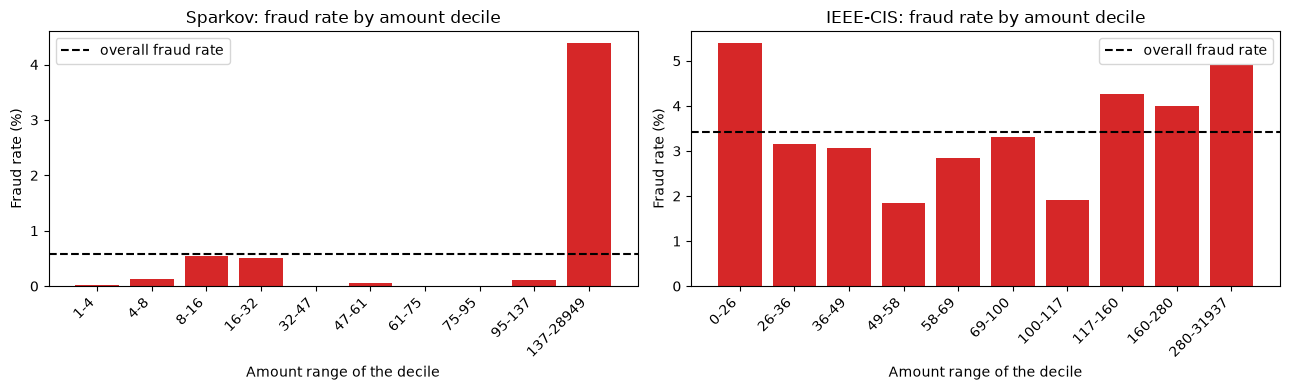

In [5]:
# fraud rate by amount decile (deciles from the training rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, name in enumerate(datasets):
    df = datasets[name]
    train = df[df["split"] == "train"]
    decile = pd.qcut(train[AMOUNT_COL[name]], 10, labels=False, duplicates="drop")
    by_decile = train.groupby(decile)["label"].mean()
    edges = train.groupby(decile)[AMOUNT_COL[name]].agg(["min", "max"])
    labels = []
    for d in by_decile.index:
        labels.append(f"{edges.loc[d, 'min']:.0f}-{edges.loc[d, 'max']:.0f}")
    axes[i].bar(range(len(by_decile)), by_decile.to_numpy() * 100, color="tab:red")
    axes[i].axhline(train["label"].mean() * 100, color="black", linestyle="--", label="overall fraud rate")
    axes[i].set_xticks(range(len(by_decile)), labels, rotation=45, ha="right")
    axes[i].set_title(f"{name}: fraud rate by amount decile")
    axes[i].set_xlabel("Amount range of the decile")
    axes[i].set_ylabel("Fraud rate (%)")
    axes[i].legend()
    print(name, "fraud rate by decile (%):", np.round(by_decile.to_numpy() * 100, 2))
plt.tight_layout()
plt.show()

In [6]:
# depth-3 tree, LR and binned LR on the same 4 raw columns
rows = []
for name in datasets:
    df = datasets[name]
    cols = RULE_COLS[name]
    train = df[df["split"] == "train"]
    val = df[df["split"] == "validation"]

    # missing values get the training median
    # all 3 models get the same input
    medians = train[cols].median()
    X_rule_train = train[cols].fillna(medians).astype(float)
    X_rule_val = val[cols].fillna(medians).astype(float)

    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    tree.fit(X_rule_train, train["label"])
    tree_score = average_precision_score(val["label"], tree.predict_proba(X_rule_val)[:, 1])

    # same preprocessing as the M0 LR: arcsinh, then standardise
    arcsinh_train = np.arcsinh(X_rule_train)
    arcsinh_val = np.arcsinh(X_rule_val)
    means = arcsinh_train.mean()
    stds = arcsinh_train.std()
    lr = LogisticRegression(max_iter=1000)
    lr.fit((arcsinh_train - means) / stds, train["label"])
    lr_score = average_precision_score(val["label"], lr.predict_proba((arcsinh_val - means) / stds)[:, 1])

    # binned LR: each column is cut into 10 bins from the training rows
    # the bins are then one-hot encoded
    binned_train = []
    binned_val = []
    for col in cols:
        edges = np.unique(np.nanquantile(X_rule_train[col], np.linspace(0, 1, 11)))
        edges[0] = -np.inf
        edges[-1] = np.inf
        binned_train.append(pd.get_dummies(pd.cut(X_rule_train[col], edges), prefix=col))
        binned_val.append(pd.get_dummies(pd.cut(X_rule_val[col], edges), prefix=col))
    binned_train = pd.concat(binned_train, axis=1).astype(float)
    binned_val = pd.concat(binned_val, axis=1).astype(float)
    binned_lr = LogisticRegression(max_iter=1000)
    binned_lr.fit(binned_train, train["label"])
    binned_score = average_precision_score(val["label"], binned_lr.predict_proba(binned_val)[:, 1])

    fraud_rate = val["label"].mean()
    rows.append({"dataset": name, "validation fraud rate": fraud_rate,
                 "depth-3 tree": tree_score, "LR": lr_score, "binned LR": binned_score,
                 "tree / fraud rate": tree_score / fraud_rate,
                 "tree - LR": tree_score - lr_score, "tree - binned LR": tree_score - binned_score})
display(pd.DataFrame(rows).set_index("dataset").round(4))

,validation fraud rate,depth-3 tree,LR,binned LR,tree / fraud rate,tree - LR,tree - binned LR
dataset,,,,,,,
Sparkov,0.0059,0.4522,0.2173,0.2607,76.2418,0.2348,0.1915
IEEE-CIS,0.0392,0.1196,0.0894,0.0999,3.0504,0.0302,0.0197


**Takeaway: M0 LR vs M0 Trees**

- Using the single-column AUC rule, the four selected features are transaction amount, seconds since the card's previous transaction, transaction hour and customer age for Sparkov, and `TransactionAmt`, `D5`, `D3` and `D2` for IEEE-CIS.

- **Fraud rate by transaction amount:** On Sparkov, the highest amount group has a fraud rate of 4.38%, while the third and fourth groups have rates of approximately 0.5%. Most other groups have fraud rates close to 0%. This suggests that fraud is concentrated in specific amount ranges rather than increasing consistently with transaction amount. In contrast, fraud rates across all 10 groups on IEEE-CIS range from 1.84% to 5.39%, meaning fraud is present across the entire amount distribution, with a smaller difference between groups.

- **Sparkov:** The depth-3 decision tree achieves a PR-AUC of 0.452 using only four features, approximately 76 times the fraud rate and almost half of the full M0 CatBoost's PR-AUC of 0.987 using 62 features. In comparison, LR achieves only 0.217 using the same four features. Binning the features improves LR to 0.261, but most of the gap with the decision tree remains (0.192 out of 0.235). This suggests that non-linear relationships within individual features do not fully explain the difference. The tree may perform better because it can also capture interactions between features, such as a large transaction amount occurring late at night, which LR cannot directly represent without additional interaction features.

- **IEEE-CIS:** All three simple models perform relatively poorly, with PR-AUC scores of 0.120 for the decision tree, 0.100 for binned LR and 0.089 for LR. The decision tree achieves approximately three times the fraud rate and outperforms LR by only 0.030, compared to 0.235 on Sparkov. This suggests that the four selected features contain less predictive information on their own, and capturing interactions between them provides a smaller improvement. Since the full M0 CatBoost achieves 0.626 using 575 features, fraud detection on IEEE-CIS appears to rely more on information spread across many features rather than a few simple rules.

- **Implications for the full M0 models:**
  - On Sparkov, fraud appears to follow relatively distinct patterns involving combinations of a few features. Tree-based models can capture these patterns through multiple splits, while LR is limited to a linear combination of its input features. Card-history features help reduce this limitation by providing useful comparisons as individual columns, such as transaction amount relative to the card's historical average. This helps explain why LR achieves 0.794 with these features but falls to 0.464 when they are removed (notebook 05_sparkov, Section 6).
  - On IEEE-CIS, fraud patterns appear less distinct, with predictive information distributed across a larger number of features. LR can combine the individual effects of these features, which may explain why its performance is closer to the tree-based models, with a PR-AUC gap of 0.099 compared to 0.194 on Sparkov.

- **Limitations:** This experiment uses only four selected features from each dataset and is intended to illustrate possible reasons for the performance gap rather than fully explain the original M0 results. In IEEE-CIS, the three selected `D` features have high missingness rates (48% to 55%) and are median-imputed. They also contain related time-gap information, which may limit the additional predictive information provided by each feature. Selecting different features could therefore produce different results.

Overall, the larger performance gap between LR and tree-based models on Sparkov may be explained by its stronger feature interactions and more distinct fraud patterns. These patterns are likely influenced by how fraud is generated in the simulator, so the Sparkov results may overstate LR's disadvantage relative to tree-based models when applied to real-world transaction data.

## 6. M0 / M1 / M2 Family Ranking

The ranking of the four model families is largely consistent across both datasets. CatBoost performs best and LR performs worst in M0, M1 and M2. The only exception is Sparkov M0, where RF outperforms LightGBM.

| | Sparkov | IEEE-CIS |
|---|---|---|
| M0 | CatBoost 0.987 > RF 0.959 > LightGBM 0.933 > LR 0.794 | CatBoost 0.626 > LightGBM 0.595 > RF 0.559 > LR 0.527 |
| M1 | CatBoost 0.989 > LightGBM 0.986 > RF 0.961 > LR 0.658 | CatBoost 0.591 > LightGBM 0.568 > RF 0.556 > LR 0.504 |
| M2 | CatBoost 0.988 > LightGBM 0.985 > RF 0.947 > LR 0.815 | CatBoost 0.653 > LightGBM 0.619 > RF 0.562 > LR 0.511 |

The Sparkov M2 results are not directly comparable with M0 and M1 (e.g. LR 0.815 vs 0.794), as M2 recalculates the three frequency features using only earlier transactions to avoid incorporating future information (notebook 05_sparkov, Section 5.2).

Some of these findings are discussed in other sections. Section 5 examines why LR performs worse than the tree-based models, while Section 7 investigates why the unweighted LightGBM model performs worse than RF on Sparkov M0 due to training instability.

To investigate the remaining differences in model rankings, we conduct two additional experiments:

- **Does RF benefit from more trees?** RF uses 100 trees, compared to 300 for LightGBM and 500 for CatBoost. However, these models construct trees differently. RF trains trees independently and averages their predictions, so increasing the number of trees mainly reduces prediction variance. In contrast, boosting models build trees sequentially, with each new tree attempting to correct errors from the previous trees. Therefore, the number of trees alone does not provide a direct comparison of their training budgets. To examine whether 100 trees are sufficient for RF, we retrain the M0 RF models with 300 trees on both datasets and compare their validation PR-AUC against the original 100-tree models.

- **Why is CatBoost's advantage over LightGBM larger on IEEE-CIS?** CatBoost outperforms LightGBM by 0.031 on IEEE-CIS M0, compared to less than 0.004 on Sparkov M1 (M1 is used for Sparkov because the unweighted LightGBM is unstable, Section 7). This difference does not appear to be explained by the number of trees or learning rate alone, as increasing LightGBM to 500 trees with a learning rate of 0.1 only improves its IEEE-CIS PR-AUC from 0.595 to 0.598 (notebook 05b, Section 7.4).

  One possible explanation is the difference in how the models handle high-cardinality categorical features. IEEE-CIS contains six code columns with up to 11,945 unique values, which account for 35.5% of LightGBM's total feature gain (notebook 05b, Section 7.3). CatBoost uses ordered target statistics to encode categorical values based on earlier observations in a permutation, helping reduce target leakage and overfitting. LightGBM instead learns splits that group categorical values together, which may be more prone to overfitting when many categories have few observations. Since Sparkov does not contain categorical features with similarly high cardinality, this difference may contribute to CatBoost's larger advantage on IEEE-CIS.

  To test this explanation, we retrain the IEEE-CIS M0 CatBoost and LightGBM models with the six code columns treated as numerical features. This prevents both models from applying their categorical handling methods to these columns. If CatBoost's performance advantage decreases, it would suggest that categorical feature handling contributes to the difference. If the gap remains similar, other differences between the models may be more important.

In [7]:
# features and labels of one split, ready for the models
def sparkov_xy(split):
    rows = sparkov[sparkov["split"] == split]
    X = rows[sparkov_feature_cols].copy()
    for col in sparkov_cat_cols:
        X[col] = X[col].fillna("missing").astype(str)
    return X, rows["label"]


def ieee_xy(split):
    if split == "train":
        return ieee_X.iloc[:IEEE_N_TRAIN], ieee["label"].iloc[:IEEE_N_TRAIN]
    return ieee_X.iloc[IEEE_N_TRAIN:], ieee["label"].iloc[IEEE_N_TRAIN:]


# the M0 RF of both model notebooks, with a chosen number of trees
def make_rf(num_cols, cat_cols, n_trees):
    preprocessor = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.float32), cat_cols)
    ])
    return make_pipeline(preprocessor, RandomForestClassifier(n_estimators=n_trees, max_features="sqrt", min_samples_leaf=20,
                                                              n_jobs=-1, random_state=SEED))


# the CatBoost of both model notebooks
# class_weights is None for M0 and "Balanced" for M1
def make_catboost(class_weights):
    return CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, auto_class_weights=class_weights,
                              random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False)


# the M0 LightGBM of both model notebooks
def make_lightgbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, objective="binary",
                              random_state=SEED, n_jobs=-1, verbosity=-1)

In [8]:
# M0 RF with 300 trees on both datasets
# the model notebooks use 100 trees
# their PR-AUC is from 05_sparkov Section 3.2 and 05_ieee Section 4.2
M0_RF_100_TREES = {"Sparkov": 0.9593, "IEEE-CIS": 0.5591}

rf_rows = []
for name in ["Sparkov", "IEEE-CIS"]:
    if name == "Sparkov":
        X_fit, y_fit = sparkov_xy("train")
        X_score, y_score = sparkov_xy("validation")
        num_cols = sparkov_num_cols
        cat_cols = sparkov_cat_cols
    else:
        X_fit, y_fit = ieee_xy("train")
        X_score, y_score = ieee_xy("validation")
        num_cols = ieee_num_cols
        cat_cols = ieee_cat_cols
    start = time.time()
    score = load_run(f"rf_300_trees_{name}")
    if score is None:
        model = make_rf(num_cols, cat_cols, 300)
        model.fit(X_fit, y_fit)
        score = average_precision_score(y_score, model.predict_proba(X_score)[:, 1])
        save_run(f"rf_300_trees_{name}", score)
        del model
    del X_fit, X_score
    gc.collect()
    rf_rows.append({"dataset": name, "100 trees (model notebook)": M0_RF_100_TREES[name], "300 trees": score,
                    "300 - 100": score - M0_RF_100_TREES[name]})
    print(f"{name}, RF with 300 trees: PR-AUC {score:.4f} ({time.time() - start:.0f}s)")
display(pd.DataFrame(rf_rows).set_index("dataset").round(4))

Sparkov, RF with 300 trees: PR-AUC 0.9595 (860s)
IEEE-CIS, RF with 300 trees: PR-AUC 0.5624 (558s)


,100 trees (model notebook),300 trees,300 - 100
dataset,,,
Sparkov,0.9593,0.9595,0.0002
IEEE-CIS,0.5591,0.5624,0.0033


In [9]:
# IEEE-CIS M0 CatBoost and M0 LightGBM
# the 6 code columns are used as categories (as in notebooks 05_ieee and 05b) and as plain numbers
X_train_ieee, y_train_ieee = ieee_xy("train")
X_val_ieee, y_val_ieee = ieee_xy("validation")


def codes_as_numbers(X):
    X = X.copy()
    for col in CODE_AS_CATEGORY:
        X[col] = pd.to_numeric(X[col].astype(str), errors="coerce").astype("float32")   # "missing" becomes NaN
    return X


ieee_scores = load_run("ieee_m0_scores")   # validation scores, also used in Section 7
if ieee_scores is None:
    ieee_scores = {}
    X_train_numbers = codes_as_numbers(X_train_ieee)
    X_val_numbers = codes_as_numbers(X_val_ieee)
    cat_cols_without_codes = []
    for col in ieee_cat_cols:
        if col not in CODE_AS_CATEGORY:
            cat_cols_without_codes.append(col)

    start = time.time()
    model = make_catboost(None)
    model.fit(X_train_ieee, y_train_ieee, cat_features=ieee_cat_cols)
    ieee_scores["M0 CatBoost"] = model.predict_proba(X_val_ieee)[:, 1]
    del model
    print(f"M0 CatBoost, codes as categories: done ({time.time() - start:.0f}s)")

    start = time.time()
    model = make_catboost(None)
    model.fit(X_train_numbers, y_train_ieee, cat_features=cat_cols_without_codes)
    ieee_scores["M0 CatBoost, codes as numbers"] = model.predict_proba(X_val_numbers)[:, 1]
    del model
    print(f"M0 CatBoost, codes as numbers: done ({time.time() - start:.0f}s)")

    model = make_lightgbm()
    model.fit(X_train_ieee, y_train_ieee)
    ieee_scores["M0 LightGBM"] = model.predict_proba(X_val_ieee)[:, 1]
    model = make_lightgbm()
    model.fit(X_train_numbers, y_train_ieee)
    ieee_scores["M0 LightGBM, codes as numbers"] = model.predict_proba(X_val_numbers)[:, 1]
    del model, X_train_numbers, X_val_numbers
    gc.collect()
    save_run("ieee_m0_scores", ieee_scores)

code_rows = []
for family in ["CatBoost", "LightGBM"]:
    as_categories = average_precision_score(y_val_ieee, ieee_scores[f"M0 {family}"])
    as_numbers = average_precision_score(y_val_ieee, ieee_scores[f"M0 {family}, codes as numbers"])
    code_rows.append({"IEEE-CIS M0 model": family, "codes as categories": as_categories, "codes as numbers": as_numbers,
                      "numbers - categories": as_numbers - as_categories})
code_table = pd.DataFrame(code_rows).set_index("IEEE-CIS M0 model")
display(code_table.round(4))
print(f"CatBoost - LightGBM, codes as categories: {code_table.loc['CatBoost', 'codes as categories'] - code_table.loc['LightGBM', 'codes as categories']:+.4f}")
print(f"CatBoost - LightGBM, codes as numbers: {code_table.loc['CatBoost', 'codes as numbers'] - code_table.loc['LightGBM', 'codes as numbers']:+.4f}")

M0 CatBoost, codes as categories: done (809s)
M0 CatBoost, codes as numbers: done (793s)


,codes as categories,codes as numbers,numbers - categories
IEEE-CIS M0 model,,,
CatBoost,0.6255,0.5801,-0.0454
LightGBM,0.5945,0.5924,-0.0022


CatBoost - LightGBM, codes as categories: +0.0310
CatBoost - LightGBM, codes as numbers: -0.0122


**Takeaway: M0 / M1 / M2 Family Ranking**

- **Increasing the number of RF trees provides little improvement:** Increasing RF from 100 to 300 trees improves PR-AUC by only 0.0002 on Sparkov (0.9593 to 0.9595) and 0.003 on IEEE-CIS (0.559 to 0.562). Even with 300 trees, RF still performs worse than LightGBM (0.595) and CatBoost (0.626) on IEEE-CIS. This suggests that RF's lower ranking is not primarily due to its smaller number of trees, and that 100 trees is sufficient for the model comparisons.

- **CatBoost's advantage on IEEE-CIS is largely explained by categorical feature handling:** When the six code columns are treated as numerical features, CatBoost's PR-AUC decreases from 0.626 to 0.580 (-0.045), while LightGBM changes only slightly (0.595 to 0.592). As a result, CatBoost's original advantage of 0.031 becomes a deficit of 0.012. This supports our earlier hypothesis that CatBoost's handling of high-cardinality categorical features contributes substantially to its stronger performance on IEEE-CIS.

- **The results are also consistent with the smaller gap on Sparkov:** Sparkov contains only three categorical columns, with the largest having 51 unique values (Section 3). Therefore, CatBoost may have less opportunity to benefit from its handling of high-cardinality categorical features. This is consistent with the similar M1 PR-AUC scores of CatBoost (0.989) and LightGBM (0.986).

Overall, the model family rankings are largely consistent across both datasets once LightGBM's training instability on Sparkov is addressed (Section 7). CatBoost generally performs best, followed by LightGBM, RF and LR. The additional experiments also show that CatBoost's advantage on IEEE-CIS is closely associated with its handling of the high-cardinality code columns, supporting its selection as the main model family for both datasets.

## 7. M1 Class Weights

M1 introduces balanced class weights for all four model families, giving each fraud transaction approximately 173 times the weight of a non-fraud transaction on Sparkov and 28 times on IEEE-CIS. These weights correspond to the ratio of non-fraud to fraud transactions in each dataset (Section 3). The table below compares the M0 and M1 results across both datasets (notebook 05_sparkov Section 4.6, notebook 05_ieee Section 5.5 and notebook 05b Section 7.1).

| | Sparkov M0 to M1 | IEEE-CIS M0 to M1 |
|---|---|---|
| **PR-AUC** | | |
| LR | 0.794 to 0.658 (-0.136) | 0.527 to 0.504 (-0.022) |
| RF | 0.9593 to 0.9605 (+0.0012) | 0.559 to 0.556 (-0.003) |
| CatBoost | 0.987 to 0.989 (+0.002) | 0.626 to 0.591 (-0.035) |
| LightGBM | 0.933 to 0.986 (+0.053) | 0.595 to 0.568 (-0.027) |
| **ROC-AUC** | | |
| LR | 0.9852 to 0.9896 | 0.8876 to 0.8878 |
| RF | 0.9981 to 0.9987 | 0.9095 to 0.9163 |
| CatBoost | 0.9997 to 0.9999 | 0.9259 to 0.9219 |
| **Precision / Recall at 0.5** | | |
| LR | 0.898 / 0.623 to 0.132 / 0.947 | 0.777 / 0.362 to 0.172 / 0.772 |
| RF | 0.980 / 0.814 to 0.796 / 0.939 | 0.889 / 0.280 to 0.533 / 0.538 |
| CatBoost | 0.984 / 0.940 to 0.852 / 0.982 | 0.810 / 0.450 to 0.321 / 0.720 |
| LightGBM | 0.949 / 0.912 to 0.870 / 0.977 | 0.843 / 0.392 to 0.373 / 0.651 |

To interpret these results, we first consider the expected effect of class weights. Assigning fraud transactions a weight of \(w\) is equivalent to repeating each fraud transaction \(w\) times in the training objective. Under an ideal model that estimates the true fraud probabilities, this would multiply the predicted fraud odds by \(w\), increasing the predicted scores without changing the ranking of transactions. We would therefore expect precision and recall at the 0.5 threshold to change, while PR-AUC and ROC-AUC remain unchanged. Changes in these ranking metrics suggest that class weights also affect the relationships learned by the model.

The results show several similarities and differences across the two datasets:

- **Precision and recall at 0.5:** Precision decreases and recall increases for all four model families on both datasets, consistent with more transactions receiving fraud predictions above the threshold.
- **RF and LR:** Both show similar trends across datasets. RF's PR-AUC changes very little, while LR performs worse after introducing class weights.
- **CatBoost:** PR-AUC improves slightly by 0.002 on Sparkov but decreases by 0.035 on IEEE-CIS.
- **LightGBM:** PR-AUC increases by 0.053 on Sparkov but decreases by 0.027 on IEEE-CIS, representing the largest difference in the effects of class weights.

To investigate the different results for LightGBM and CatBoost, we conduct two additional analyses:

- **Why do class weights improve LightGBM on Sparkov?** LightGBM calculates leaf updates using the sum of gradients divided by the sum of Hessians. For a fraud transaction with predicted probability \(p\), the gradient is \(p-1\), while the Hessian is \(p(1-p)\). For a leaf containing only fraud transactions, the update therefore has a magnitude of approximately \(1/p\), before accounting for regularisation and the learning rate.

  Without class weights, the initial predicted probability is approximately equal to the fraud rate. This results in an initial leaf update of around 174 on Sparkov (\(1/0.0058\)), compared to 29 on IEEE-CIS (\(1/0.0341\)). With balanced class weights, the initial probability is approximately 0.5, reducing the update magnitude to around 2.

  Since LightGBM does not apply L2 regularisation by default (`reg_lambda=0`), these large updates may lead to training instability on Sparkov. CatBoost, in comparison, applies L2 regularisation by default (`l2_leaf_reg=3`). This suggests that class weights may improve LightGBM's performance by stabilising training rather than directly improving its ability to rank fraudulent transactions.

  To test this explanation, we conduct four experiments, recording validation PR-AUC after each tree and the largest leaf value:

  - **Increasing the number of trees:** Retrain M0 and M1 with 1,000 trees to determine whether the unweighted model simply requires more boosting rounds.
  - **Adjusting the training settings:** Retrain M0 with 500 trees and a learning rate of 0.1, following the larger training budget tested on IEEE-CIS (notebook 05b, Section 7.4).
  - **Adding L2 regularisation:** Retrain M0 with `reg_lambda=10` and no class weights to examine whether limiting leaf updates can improve training stability.
  - **Reducing class weights:** Test weights of 5, 13 and 28 instead of 173 to determine whether the improvement depends on the magnitude of the weight.

- **Why do class weights reduce CatBoost's PR-AUC on IEEE-CIS?** One possible explanation is the greater overlap between fraud and non-fraud transactions, including fraud-labelled transactions with features similar to legitimate purchases (Section 4). When each fraud transaction receives approximately 28 times more weight, CatBoost may also assign higher fraud scores to non-fraud transactions with similar characteristics. This could reduce precision among the highest-ranked transactions and contribute to the decline in PR-AUC.

  To examine this explanation, we compare the M0 and M1 CatBoost predictions on IEEE-CIS in three ways:

  - **Fraud among the highest-ranked transactions:** Compare the proportion of actual fraud transactions among the highest predicted scores to determine whether M1 loses precision at the top of the ranking.
  - **Fraud with and without previous fraud on the same card:** Compare the rankings of fraudulent transactions based on whether the card has an earlier fraud transaction, to identify which group is more affected by class weights.
  - **Non-fraud transactions among the highest-ranked predictions:** Examine whether the additional non-fraud transactions receiving high scores in M1 are associated with cards that have an earlier fraud transaction.

Sparkov fraud rate 0.5753% => first step of a fraud-only leaf without weights: 174
IEEE-CIS fraud rate 3.4119% => first step of a fraud-only leaf without weights: 29
M0 (no weights): 0.9640 (129s)
M1 (balanced weights, about 173): 0.9904 (106s)
M0 + L2 penalty 10: 0.9872 (117s)
M0, learning rate 0.1: 0.7567 (38s)
M0 + L2 penalty 10, learning rate 0.1: 0.9864 (60s)
weight 5: 0.8498 (42s)
weight 13: 0.9870 (34s)
weight 28 (the IEEE-CIS ratio): 0.9866 (43s)


,trees,learning rate,PR-AUC at 300 trees,PR-AUC at the last tree,largest one-tree drop,largest leaf value
run,,,,,,
M0 (no weights),1000,0.05,0.9325,0.9640,-0.0284,612.0544
"M1 (balanced weights, about 173)",1000,0.05,0.9857,0.9904,-0.0071,10.9273
M0 + L2 penalty 10,1000,0.05,0.9845,0.9872,-0.0000,1.0204
"M0, learning rate 0.1",500,0.10,0.3537,0.7567,-0.4625,774183.6493
"M0 + L2 penalty 10, learning rate 0.1",500,0.10,0.9856,0.9864,-0.0001,1.1711
weight 5,300,0.05,0.8498,0.8498,-0.0716,112.1646
weight 13,300,0.05,0.9870,0.9870,-0.0003,8.0023
weight 28 (the IEEE-CIS ratio),300,0.05,0.9866,0.9866,-0.0014,6.0489


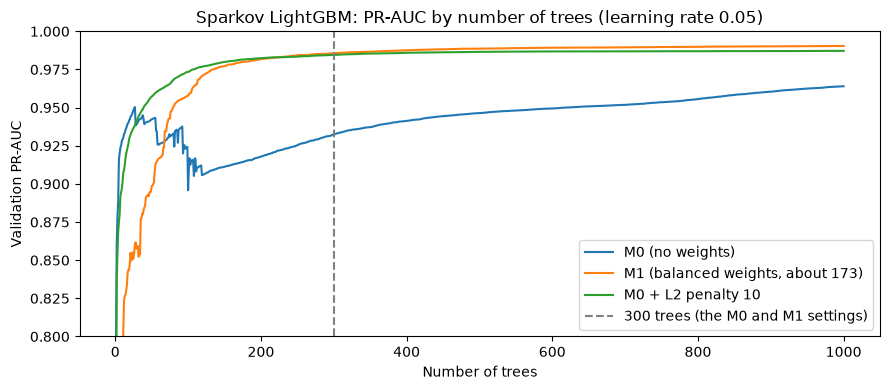

In [10]:
# Sparkov LightGBM with class weights, more trees and an L2 penalty
# the validation PR-AUC is recorded after every tree
X_train_lgb, y_train_sparkov = sparkov_xy("train")
X_val_lgb, y_val_sparkov = sparkov_xy("validation")
for col in sparkov_cat_cols:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_val_lgb[col] = pd.Categorical(X_val_lgb[col], categories=X_train_lgb[col].cat.categories)
print(f"Sparkov fraud rate {y_train_sparkov.mean():.4%} => first step of a fraud-only leaf without weights: {1 / y_train_sparkov.mean():.0f}")
print(f"IEEE-CIS fraud rate {y_train_ieee.mean():.4%} => first step of a fraud-only leaf without weights: {1 / y_train_ieee.mean():.0f}")

# each run: name, trees, learning rate, class weight and L2 penalty
runs = [("M0 (no weights)", 1000, 0.05, None, 0),
        ("M1 (balanced weights, about 173)", 1000, 0.05, "balanced", 0),
        ("M0 + L2 penalty 10", 1000, 0.05, None, 10),
        ("M0, learning rate 0.1", 500, 0.1, None, 0),
        ("M0 + L2 penalty 10, learning rate 0.1", 500, 0.1, None, 10),
        ("weight 5", 300, 0.05, {0: 1, 1: 5}, 0),
        ("weight 13", 300, 0.05, {0: 1, 1: 13}, 0),
        ("weight 28 (the IEEE-CIS ratio)", 300, 0.05, {0: 1, 1: 28}, 0)]

rows = []
curves = {}
run_number = 0
for run_name, n_estimators, learning_rate, class_weight, reg_lambda in runs:
    run_number = run_number + 1
    start = time.time()
    saved = load_run(f"sparkov_lightgbm_run{run_number}")
    if saved is not None:
        curves[run_name] = saved["curve"]
        rows.append(saved["row"])
        continue
    model = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=learning_rate, num_leaves=31, max_depth=-1, objective="binary",
                               class_weight=class_weight, reg_lambda=reg_lambda, random_state=SEED, n_jobs=-1, verbosity=-1)
    # PR-AUC after every tree is only used to show the behaviour
    # it is not used to choose the number of trees
    record = {}
    model.fit(X_train_lgb, y_train_sparkov, categorical_feature=sparkov_cat_cols, eval_X=X_val_lgb, eval_y=y_val_sparkov,
              eval_metric="average_precision", callbacks=[lgb.record_evaluation(record)])
    curve = np.array(record["valid_0"]["average_precision"])
    curves[run_name] = curve

    # largest leaf value, skipping the first tree
    # the first tree also holds the starting score
    trees = model.booster_.trees_to_dataframe()
    leaves = trees[trees["split_feature"].isna() & (trees["tree_index"] > 0)]
    row = {"run": run_name, "trees": n_estimators, "learning rate": learning_rate, "PR-AUC at 300 trees": curve[299],
           "PR-AUC at the last tree": curve[-1], "largest one-tree drop": (curve[1:] - curve[:-1]).min(),
           "largest leaf value": leaves["value"].abs().max()}
    rows.append(row)
    save_run(f"sparkov_lightgbm_run{run_number}", {"curve": curve, "row": row})
    del model, trees, leaves
    print(f"{run_name}: {curve[-1]:.4f} ({time.time() - start:.0f}s)")
del X_train_lgb, X_val_lgb
gc.collect()

display(pd.DataFrame(rows).set_index("run").round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for run_name in ["M0 (no weights)", "M1 (balanced weights, about 173)", "M0 + L2 penalty 10"]:
    ax.plot(range(1, len(curves[run_name]) + 1), curves[run_name], label=run_name)
ax.axvline(300, color="grey", linestyle="--", label="300 trees (the M0 and M1 settings)")
ax.set_ylim(0.8, 1.0)
ax.set_xlabel("Number of trees")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Sparkov LightGBM: PR-AUC by number of trees (learning rate 0.05)")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# IEEE-CIS M1 CatBoost
# the M0 scores are from Section 6
ieee_scores["M1 CatBoost"] = load_run("ieee_m1_catboost_scores")
if ieee_scores["M1 CatBoost"] is None:
    start = time.time()
    model = make_catboost("Balanced")
    model.fit(X_train_ieee, y_train_ieee, cat_features=ieee_cat_cols)
    ieee_scores["M1 CatBoost"] = model.predict_proba(X_val_ieee)[:, 1]
    save_run("ieee_m1_catboost_scores", ieee_scores["M1 CatBoost"])
    del model
    print(f"M1 CatBoost: done ({time.time() - start:.0f}s)")
for name in ["M0 CatBoost", "M1 CatBoost"]:
    print(f"{name}: PR-AUC {average_precision_score(y_val_ieee, ieee_scores[name]):.4f}")

# number of earlier frauds on the same card
# rows without a card ID count as 0
ordered = ieee.sort_values("time", kind="stable")
earlier_frauds = ordered.groupby("card")["label"].cumsum() - ordered["label"]
ieee["earlier_frauds_on_card"] = earlier_frauds.reindex(ieee.index).fillna(0)
del ordered

val_ieee = ieee[ieee["split"] == "validation"]
y = val_ieee["label"].to_numpy()
after_fraud = (val_ieee["earlier_frauds_on_card"] > 0).to_numpy()
n_frauds = int(y.sum())

# (a) share of fraud among the highest-scored rows
top_rows = []
for share in [0.005, 0.01, 0.02, 0.05, 0.10]:
    n_top = int(len(y) * share)
    row = {"highest-scored rows": f"top {share:.1%} ({n_top:,} rows)"}
    for name in ["M0 CatBoost", "M1 CatBoost"]:
        order = np.argsort(-ieee_scores[name], kind="stable")
        row[name] = y[order[:n_top]].mean()
    row["M1 - M0"] = row["M1 CatBoost"] - row["M0 CatBoost"]
    top_rows.append(row)
print("(a) share of fraud among the highest-scored validation rows:")
display(pd.DataFrame(top_rows).set_index("highest-scored rows").round(4))

# (b) frauds on a card with an earlier fraud and frauds on a card without one
group_rows = []
for group_name, in_group in [("frauds after an earlier fraud on the card", after_fraud), ("frauds with no earlier fraud on the card", ~after_fraud)]:
    group_frauds = (y == 1) & in_group
    keep = group_frauds | (y == 0)   # the frauds of this group against all non-fraud rows
    row = {"group": group_name, "frauds": int(group_frauds.sum())}
    for name in ["M0 CatBoost", "M1 CatBoost"]:
        scores = ieee_scores[name]
        order = np.argsort(-scores, kind="stable")
        in_top = np.zeros(len(y), dtype=bool)
        in_top[order[:n_frauds]] = True
        row[f"{name}: PR-AUC"] = average_precision_score(group_frauds[keep], scores[keep])
        row[f"{name}: share in the top {n_frauds:,}"] = (group_frauds & in_top).sum() / group_frauds.sum()
    row["PR-AUC, M1 - M0"] = row["M1 CatBoost: PR-AUC"] - row["M0 CatBoost: PR-AUC"]
    group_rows.append(row)
print("(b) by kind of fraud:")
display(pd.DataFrame(group_rows).set_index("group").round(4))

# (c) non-fraud rows among the top rows
# the top has as many rows as there are frauds
false_rows = []
for name in ["M0 CatBoost", "M1 CatBoost"]:
    order = np.argsort(-ieee_scores[name], kind="stable")
    top = order[:n_frauds]
    non_fraud_top = top[y[top] == 0]
    false_rows.append({"model": name, f"non-fraud rows in the top {n_frauds:,}": len(non_fraud_top),
                       "of these, on a card with an earlier fraud": int(after_fraud[non_fraud_top].sum()),
                       "of these, on a card with no earlier fraud": int((~after_fraud[non_fraud_top]).sum())})
print("(c) non-fraud rows among the top rows:")
display(pd.DataFrame(false_rows).set_index("model"))
print(f"validation rows on a card with an earlier fraud: {after_fraud.sum():,}, of which fraud: {y[after_fraud].mean():.1%}")

M1 CatBoost: done (858s)
M0 CatBoost: PR-AUC 0.6255
M1 CatBoost: PR-AUC 0.5906
(a) share of fraud among the highest-scored validation rows:


,M0 CatBoost,M1 CatBoost,M1 - M0
highest-scored rows,,,
top 0.5% (472 rows),0.9725,0.9174,-0.0551
top 1.0% (944 rows),0.9311,0.8919,-0.0392
"top 2.0% (1,889 rows)",0.8317,0.8041,-0.0275
"top 5.0% (4,724 rows)",0.4994,0.4826,-0.0167
"top 10.0% (9,448 rows)",0.2951,0.2918,-0.0033


(b) by kind of fraud:


,frauds,M0 CatBoost: PR-AUC,"M0 CatBoost: share in the top 3,704",M1 CatBoost: PR-AUC,"M1 CatBoost: share in the top 3,704","PR-AUC, M1 - M0"
group,,,,,,
frauds after an earlier fraud on the card,2348,0.5794,0.6086,0.5201,0.5737,-0.0593
frauds with no earlier fraud on the card,1356,0.4757,0.5730,0.4499,0.5619,-0.0258


(c) non-fraud rows among the top rows:


,"non-fraud rows in the top 3,704","of these, on a card with an earlier fraud","of these, on a card with no earlier fraud"
model,,,
M0 CatBoost,1498,177,1321
M1 CatBoost,1595,135,1460


validation rows on a card with an earlier fraud: 5,046, of which fraud: 46.5%


**Takeaway: M1 Class Weights**

**LightGBM on Sparkov**

- **The unweighted LightGBM model is unstable:** With 300 trees, M0 achieves a PR-AUC of 0.933, with a drop of 0.028 after a single tree and a maximum leaf value of 612. These large leaf updates can substantially affect the predicted probabilities and lead to unstable performance. Increasing the number of trees to 1,000 improves M0 to 0.964, but it still performs worse than M1 (0.990). This suggests that the lower M0 performance is not simply due to having too few trees.

- **Increasing the training budget does not resolve the instability:** With 500 trees and a learning rate of 0.1, the maximum leaf value increases to approximately 774,000, and a single tree causes a PR-AUC drop of 0.46. The final PR-AUC falls to 0.757. In comparison, the same training settings do not cause instability on IEEE-CIS (notebook 05b, Section 7.4). This suggests that increasing the learning rate may worsen the instability on Sparkov.

- **L2 regularisation resolves the instability without class weights:** Adding `reg_lambda=10` to M0 improves PR-AUC to 0.985 with 300 trees, close to M1's 0.986. The model no longer experiences sudden performance drops between trees, and its maximum leaf value decreases to approximately 1. With a learning rate of 0.1, adding L2 regularisation also improves PR-AUC from 0.757 to 0.986. These results support the explanation that the instability is related to excessively large leaf updates rather than the absence of class weights.

- **Smaller class weights are sufficient:** Using class weights of 13 or 28 achieves a PR-AUC of 0.987, similar to the balanced weight of approximately 173 (0.986). In contrast, a weight of 5 produces a lower PR-AUC of 0.850, with a maximum leaf value of 112. This suggests that sufficiently large class weights help stabilise training by reducing the magnitude of the leaf updates, rather than requiring the full balanced weight.

- **Why the same issue does not occur on IEEE-CIS:** IEEE-CIS has a higher fraud rate of 3.4%, giving an approximate initial update of 29 for a fraud-only leaf, compared to 174 on Sparkov. The unweighted LightGBM model on IEEE-CIS does not show the same instability, so class weights provide no similar benefit and instead reduce PR-AUC by 0.027.

**CatBoost on IEEE-CIS**

- **The performance decline is concentrated at the top of the ranking:** Among the highest-scored 0.5% of validation transactions, precision decreases from 97.3% in M0 to 91.7% in M1, a drop of approximately 5.5 percentage points. The difference becomes smaller as more transactions are included, decreasing by 0.039 for the top 1%, 0.017 for the top 5% and only 0.003 for the top 10%. This shows that class weights mainly affect the highest-ranked transactions, helping explain why PR-AUC decreases by 0.035 while ROC-AUC changes relatively little.

- **Both groups of fraudulent transactions are ranked less effectively:** For fraud transactions on cards with an earlier fraud, PR-AUC decreases from 0.579 to 0.520 (-0.059). For transactions without earlier fraud on the same card, it decreases from 0.476 to 0.450 (-0.026). The decline is therefore larger for fraudulent transactions associated with previously fraudulent cards.

- **The additional high-scored non-fraud transactions are mainly from cards without earlier fraud:** Among the 3,704 highest-ranked transactions, corresponding to the number of fraud cases in the validation set, M1 includes 1,595 non-fraud transactions compared to 1,498 in M0. The number from cards without earlier fraud increases from 1,321 to 1,460, while the number from cards with earlier fraud decreases from 177 to 135. This does not support our initial hypothesis that the additional high-scored non-fraud transactions would primarily come from cards with earlier fraud.

- **Interpretation of the results:** The results confirm that class weights reduce precision among the highest-ranked transactions, but do not support our initial hypothesis that the additional non-fraud transactions come from cards with earlier fraud. A possible explanation is that, with fraud transactions weighted approximately 28 times more heavily, CatBoost places greater emphasis on detecting fraud cases that resemble normal purchases. As a result, it may also assign higher fraud scores to genuinely legitimate transactions with similar features. These non-fraud transactions then move into the top ranks, displacing fraud cases that M0 had previously ranked correctly.

**Other Model Families and Overall Findings**

- **Precision and recall at the 0.5 threshold:** Precision decreases and recall increases for all four model families on both datasets. This is consistent with class weights generally increasing predicted fraud scores, causing more transactions to be classified as fraud at the same threshold. A similar increase in recall may also be achieved by lowering the decision threshold of M0, without retraining the model.

- **RF shows little change on both datasets:** PR-AUC increases by only 0.001 on Sparkov and decreases by 0.003 on IEEE-CIS. Within a fixed tree, class weights change the fraud proportion in each leaf to a weighted proportion, which preserves the ordering of leaves by their original fraud proportions. Although class weights can influence how the trees are constructed, the small changes in PR-AUC suggest that RF learns similar rankings with and without weighting.

- **LR performs worse on both datasets:** PR-AUC decreases by 0.136 on Sparkov and 0.022 on IEEE-CIS, although ROC-AUC increases slightly on both. As discussed in Section 5, LR cannot fully capture the underlying non-linear relationships and feature interactions. Adding class weights changes the fitted model by placing greater emphasis on identifying fraud cases. This may improve overall separation while allowing more non-fraud transactions to appear among the highest scores, reducing PR-AUC. The decline is larger on Sparkov, where the class weight is approximately six times higher and LR has greater difficulty capturing the fraud patterns.

- **CatBoost shows little improvement on Sparkov:** PR-AUC increases by only 0.002. CatBoost already achieves a ROC-AUC of 0.9997 on Sparkov, which means it separates the two classes almost perfectly in M0. This leaves very little room for class weights to improve the ranking further.

Overall, class weights do not consistently improve PR-AUC for models that already train reliably. They have little effect on RF, reduce LR performance on both datasets and reduce the performance of CatBoost and LightGBM on IEEE-CIS. The only substantial improvement occurs for LightGBM on Sparkov, where class weights help resolve training instability caused by the low fraud rate. Since L2 regularisation produces a similar improvement without class weights, this should not be interpreted as evidence that class weighting is generally more effective on Sparkov than on IEEE-CIS.

## 8. M0 Card-History Features

Both datasets include features derived from earlier transactions made using the same card, with 25 card-history features in Sparkov and 57 in IEEE-CIS. However, removing these features from the M0 models leads to substantial decreases in PR-AUC on Sparkov, while the effect on IEEE-CIS is much smaller (notebook 05_sparkov Section 6 and notebook 05_ieee Section 6). On IEEE-CIS, these features also provide little improvement after introducing the 7-day label delay in M2, increasing M2 CatBoost's PR-AUC by only 0.002 (notebook 05_ieee, Section 9.6). No additional code is required for this section.

| M0 without card history | Sparkov | IEEE-CIS |
|---|---|---|
| LR | 0.794 to 0.464 (-0.329) | 0.527 to 0.528 (+0.001) |
| RF | 0.959 to 0.889 (-0.071) | 0.559 to 0.555 (-0.004) |
| CatBoost | 0.987 to 0.925 (-0.062) | 0.626 to 0.616 (-0.010) |

Several factors may explain why card-history features are more useful on Sparkov:

- **Sparkov has much longer transaction histories per card:** Card-history features compare a transaction with earlier transactions made using the same card. As shown in Section 3, Sparkov has a median of 1,147 transactions per card, providing more historical information about typical spending behaviour. In comparison, IEEE-CIS has a median of only one transaction per card, meaning many transactions have little or no previous activity to compare against. As a result, card-history features may be missing or calculated from very few observations. Furthermore, IEEE-CIS uses reconstructed card IDs (notebook 03, Section 10), which may occasionally group transactions from different cards together and reduce the reliability of these features.

- **Sparkov fraud often involves sudden changes in card behaviour:** Our earlier analysis in notebook 02 (*Card history patterns*) shows that fraudulent transactions tend to occur shortly after the previous transaction, with a median gap of 1.4 hours compared to 4.6 hours for non-fraud transactions. Fraud also tends to occur in bursts of approximately 10 transactions over 1.9 days. Card-history features, such as transaction amount relative to the card's historical average and the number of transactions in the past hour, can capture these changes in behaviour. Since a card's historical spending average is not directly available in the raw features, even CatBoost experiences a substantial PR-AUC drop of 0.062 when card-history features are removed.

- **IEEE-CIS already contains some similar information:** The original `C` features contain count-related information, while the `D` features represent time-related information. These may already capture some of the patterns that our additional card-history features are designed to identify. Furthermore, the original features were created by the data provider, which may have access to more reliable transaction links than our reconstructed card IDs. This could explain why removing the additional card-history features has little effect on IEEE-CIS. However, we cannot confirm how much information overlaps because the exact construction of the original features is not available.

- **LR is most affected by removing card-history features on Sparkov:** LR experiences the largest PR-AUC drop of 0.329, compared to 0.071 for RF and 0.062 for CatBoost. As discussed in Section 5, LR cannot directly capture complex interactions between raw features. Card-history features provide useful comparisons as individual columns, allowing LR to use information that it would otherwise struggle to derive. In contrast, tree-based models can still capture some related patterns from raw features such as transaction amount, hour and category, resulting in smaller performance drops.

Overall, card-history features provide important predictive information on Sparkov, where cards have long transaction histories and fraud tends to involve changes in spending behaviour. In contrast, most IEEE-CIS cards have limited transaction histories, while some similar information may already be captured by the original `C` and `D` features. This helps explain why the additional card-history features provide much smaller improvements on IEEE-CIS.

## 9. M2 Retraining

M2 introduces scheduled model retraining using only fraud labels that are at least 7 days old. We compare its performance against a static model trained once at the beginning of the validation period. The results show that retraining provides little improvement on Sparkov but improves PR-AUC across all four model families on IEEE-CIS (notebook 05_sparkov Section 5.7, notebook 05_ieee Section 9.4 and notebook 05c Section 7.1).

| Validation PR-AUC | Sparkov static to M2 | IEEE-CIS static to M2 |
|---|---|---|
| CatBoost | 0.9866 to 0.9877 (+0.0012) | 0.601 to 0.653 (+0.053) |
| LightGBM | 0.9856 to 0.9852 (-0.0003) | 0.572 to 0.619 (+0.047) |
| RF | 0.9451 to 0.9471 (+0.0020) | 0.546 to 0.562 (+0.017) |
| LR | 0.8131 to 0.8149 (+0.0018) | 0.501 to 0.511 (+0.010) |

The earlier notebooks provide some possible explanations for these differences:

- **Sparkov shows little change over time:** The feature distributions remain relatively stable, with PSI values below 0.03 (notebook 04b). A model trained once also maintains a ROC-AUC between 0.993 and 0.999 throughout the evaluation period (notebook 04c, Section 3). Since Sparkov is simulated using relatively consistent fraud patterns, newer transactions may provide little additional information beyond what the model has already learned from over one million training transactions.

- **IEEE-CIS shows greater changes over time:** Some features experience substantial distribution shifts, such as `D15` with a PSI of 0.48. The relationship between features and fraud also changes, with the fraud rate in the lowest transaction amount group increasing from 5.0% to 6.2% (notebook 04b). These changes may reduce how well a model trained on earlier transactions performs on newer data. For example, the static CatBoost model generally declines across the reported validation periods, with PR-AUC scores of 0.675, 0.606, 0.631, 0.532 and 0.444. In comparison, M2 achieves 0.675, 0.648, 0.685, 0.648 and 0.573, maintaining better performance over time (notebook 05_ieee, Section 9.4). This suggests that retraining becomes increasingly useful as the static model becomes outdated. The relationship between weekly data drift and model performance is examined further in notebook 05d (Section 5).

To investigate the reasons for the different effects of retraining, we conduct two additional analyses:

- **Does repeated fraud on the same card explain the improvement on IEEE-CIS?** As shown in notebook 04b, 60.2% of fraudulent transactions occur on cards with an earlier fraud transaction. Retraining allows the model to learn from more recent fraud-labelled transactions, including newly observed card values, whereas the static model is limited to information available at the beginning of validation. This may also explain why CatBoost and LightGBM benefit more from retraining (+0.053 and +0.047). These models can learn patterns associated with specific categorical values, while LR groups code values with fewer than 500 observations together and RF treats encoded codes as ordered numbers.

  To examine this, we use the saved validation predictions from notebooks 05_ieee and 05c and divide the fraudulent transactions into three groups:

  - **Previously known fraud cards:** Cards with an earlier fraud label available to both the static model and M2.
  - **Newly known fraud cards:** Cards with an earlier fraud label available only to M2, because the label became available after the static model was trained.
  - **Cards without known fraud:** Cards with no earlier fraud label available to either model.

  For each group, we calculate PR-AUC using the fraud transactions in that group against all non-fraud validation transactions, comparing the static and M2 predictions. If repeated fraud is an important reason for the improvement, we would expect the largest gain among newly known fraud cards, particularly for CatBoost and LightGBM.

- **How much does the 7-day label delay affect Sparkov?** On IEEE-CIS, the label delay reduces M2 PR-AUC by approximately 0.04. Without the delay, CatBoost would achieve 0.692 instead of 0.653, while LightGBM would achieve 0.663 instead of 0.619 (notebook 05_ieee Section 9.4 and notebook 05c Section 7.1).

  Since this was not previously tested on Sparkov, we repeat the M2 experiment using a 0-day label delay for all four model families, keeping the model settings and retraining frequencies unchanged. As Sparkov fraud tends to occur in bursts lasting approximately two days on the same card, a 7-day delay means that the labels from a fraud burst would generally only become available after the burst has ended. If access to these recent fraud labels is important, we would expect the 0-day delay to produce a noticeable improvement in PR-AUC.

In [12]:
# IEEE-CIS: where the gain from retraining comes from
# uses the validation scores saved by notebook 05_ieee with the 7-day label delay
val_ieee = ieee[ieee["split"] == "validation"]
y = val_ieee["label"].to_numpy()
VAL_FIRST_DAY = int(val_ieee["day"].min())
static_label_end = VAL_FIRST_DAY - LABEL_DELAY_DAYS   # the static model has the labels before this day

# the retrained model for a row has the labels before its week start minus the delay
week_start = VAL_FIRST_DAY + 7 * ((val_ieee["day"] - VAL_FIRST_DAY) // 7)
m2_label_end = week_start - LABEL_DELAY_DAYS

# first fraud day of each card over all days
# and first fraud day after the static model stops seeing labels
frauds = ieee[(ieee["label"] == 1) & ieee["card"].notna()]
first_fraud_day = frauds.groupby("card")["day"].min()
first_new_fraud_day = frauds[frauds["day"] >= static_label_end].groupby("card")["day"].min()
card_first = val_ieee["card"].map(first_fraud_day)
card_first_new = val_ieee["card"].map(first_new_fraud_day)

known_to_both = (card_first < static_label_end).to_numpy()
known_to_m2_only = ((card_first_new < m2_label_end) & ~(card_first < static_label_end)).to_numpy()
groups = {"card had a labelled fraud that both models saw": known_to_both,
          "card had a labelled fraud that only M2 saw": known_to_m2_only,
          "no labelled fraud on the card for either model": ~known_to_both & ~known_to_m2_only}

score_files = {"CatBoost": ("val_static_CatBoost_windowall_delay7", "val_m2_CatBoost_freq7_windowall_delay7"),
               "LightGBM": ("val_static_LightGBM_windowall_delay7", "val_m2_LightGBM_freq7_windowall_delay7"),
               "RF": ("val_static_RF_windowall_delay7", "val_m2_RF_freq7_windowall_delay7"),
               "LR": ("val_static_LR_window56_delay7", "val_m2_LR_freq7_window56_delay7")}
gain_rows = []
for family in score_files:
    static_file, m2_file = score_files[family]
    if not (IEEE_M2_SCORES_DIR / f"{static_file}.pkl").exists():
        print(f"{family}: no saved scores, left out")
        continue
    static_scores = pd.read_pickle(IEEE_M2_SCORES_DIR / f"{static_file}.pkl").loc[val_ieee.index].to_numpy()
    m2_scores = pd.read_pickle(IEEE_M2_SCORES_DIR / f"{m2_file}.pkl").loc[val_ieee.index].to_numpy()
    row = {"family": family, "all frauds: static": average_precision_score(y, static_scores),
           "all frauds: M2 - static": average_precision_score(y, m2_scores) - average_precision_score(y, static_scores)}
    for group_name in groups:
        group_frauds = (y == 1) & groups[group_name]
        keep = group_frauds | (y == 0)   # the frauds of this group against all non-fraud rows
        static_ap = average_precision_score(group_frauds[keep], static_scores[keep])
        m2_ap = average_precision_score(group_frauds[keep], m2_scores[keep])
        row[f"{group_name}: static"] = static_ap
        row[f"{group_name}: M2 - static"] = m2_ap - static_ap
    gain_rows.append(row)

count_rows = []
for group_name in groups:
    in_group = groups[group_name]
    count_rows.append({"group": group_name, "validation rows": int(in_group.sum()), "frauds": int(y[in_group].sum()),
                       "share of all frauds": y[in_group].sum() / y.sum(), "fraud rate": y[in_group].mean()})
display(pd.DataFrame(count_rows).set_index("group").round(4))
print("PR-AUC of the frauds of each group against all non-fraud rows:")
display(pd.DataFrame(gain_rows).set_index("family").T.round(4))

,validation rows,frauds,share of all frauds,fraud rate
group,,,,
card had a labelled fraud that both models saw,1120,659,0.1779,0.5884
card had a labelled fraud that only M2 saw,325,231,0.0624,0.7108
no labelled fraud on the card for either model,93042,2814,0.7597,0.0302


PR-AUC of the frauds of each group against all non-fraud rows:


family,CatBoost,LightGBM,RF,LR
all frauds: static,0.6008,0.5722,0.5458,0.5013
all frauds: M2 - static,0.0526,0.0465,0.0166,0.0099
card had a labelled fraud that both models saw: static,0.4126,0.3092,0.1194,0.0927
card had a labelled fraud that both models saw: M2 - static,0.0849,0.0847,0.0187,0.0083
card had a labelled fraud that only M2 saw: static,0.0929,0.0898,0.0982,0.1095
card had a labelled fraud that only M2 saw: M2 - static,0.3843,0.1078,0.0295,0.0258
no labelled fraud on the card for either model: static,0.5642,0.5459,0.5653,0.5215
no labelled fraud on the card for either model: M2 - static,0.0229,0.0214,0.0120,0.0093


In [13]:
# Sparkov: cost of the 7-day label delay
# notebook 05_ieee does the same check for IEEE-CIS
# the 7-day results come from 05_sparkov (Section 5.7)
# so only the 0-day delay is run here
# same data preparation and retraining loop as 05_sparkov Sections 5.2 to 5.5
# the window is all earlier days
# the predictions are saved so a rerun loads them
SPARKOV_DELAY_DIR = Path("../results/sparkov/delay_check")
SPARKOV_DELAY_DIR.mkdir(parents=True, exist_ok=True)
m2_df = pd.read_pickle(PROCESSED_DIR / "sparkov_features.pkl")
m2_df["trans_date_trans_time"] = pd.to_datetime(m2_df["trans_date_trans_time"])
m2_df = m2_df.loc[m2_df["sparkov_split"].isin(["train", "validation"])].copy()
m2_df = m2_df.sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True)
for feature, source in [("merchant_freq", "merchant"), ("category_freq", "category"), ("state_freq", "state")]:
    previous_rows = m2_df.groupby(source, dropna=False).cumcount()
    same_timestamp_previous = m2_df.groupby([source, "trans_date_trans_time"], dropna=False).cumcount()
    m2_df[feature] = (previous_rows - same_timestamp_previous).astype("int64")
for col in sparkov_cat_cols:
    m2_df[col] = m2_df[col].fillna("Missing").astype(str)
m2_time = m2_df["trans_date_trans_time"]
is_validation = m2_df["sparkov_split"].eq("validation")
val_start = m2_time[is_validation].min()
val_end = m2_time[is_validation].max() + pd.Timedelta(microseconds=1)


def arcsinh_m2(X):
    return np.arcsinh(X)


# the model each family uses in Sparkov M2
# LR uses M0 and the 3 tree families use M1
def make_sparkov_m2_model(family):
    if family == "LR":
        preprocessor = ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(arcsinh_m2), StandardScaler()), sparkov_num_cols),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), sparkov_cat_cols)
        ])
        return make_pipeline(preprocessor, LogisticRegression(C=1.0, max_iter=2000))
    if family == "RF":
        preprocessor = ColumnTransformer([
            ("num", "passthrough", sparkov_num_cols),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), sparkov_cat_cols)
        ])
        return make_pipeline(preprocessor, RandomForestClassifier(n_estimators=100, max_features="sqrt", min_samples_leaf=20,
                                                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))
    if family == "CatBoost":
        return CatBoostClassifier(iterations=500, learning_rate=0.1, depth=6, loss_function="Logloss", cat_features=sparkov_cat_cols,
                                  auto_class_weights="Balanced", thread_count=-1, random_seed=SEED, verbose=False, allow_writing_files=False)
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, objective="binary",
                              class_weight="balanced", random_state=SEED, n_jobs=-1, verbosity=-1)


# at every cutoff, retrain on the rows whose label is already known
# then score the rows until the next cutoff
def run_sparkov_m2(family, frequency, delay):
    y_true = []
    y_score = []
    for cutoff in pd.date_range(start=val_start, end=val_end, freq=f"{frequency}D", inclusive="left"):
        next_cutoff = min(cutoff + pd.Timedelta(days=frequency), val_end)
        fit_rows = m2_time < cutoff - pd.Timedelta(days=delay)
        score_rows = is_validation & (m2_time >= cutoff) & (m2_time < next_cutoff)
        X_fit = m2_df.loc[fit_rows, sparkov_feature_cols]
        X_block = m2_df.loc[score_rows, sparkov_feature_cols]
        model = make_sparkov_m2_model(family)
        if family == "LightGBM":
            X_fit = X_fit.copy()
            X_block = X_block.copy()
            for col in sparkov_cat_cols:
                X_fit[col] = X_fit[col].astype("category")
                X_block[col] = pd.Categorical(X_block[col], categories=X_fit[col].cat.categories)
            model.fit(X_fit, m2_df.loc[fit_rows, "is_fraud"], categorical_feature=sparkov_cat_cols)
        else:
            model.fit(X_fit, m2_df.loc[fit_rows, "is_fraud"])
        y_score.append(model.predict_proba(X_block)[:, 1])
        y_true.append(m2_df.loc[score_rows, "is_fraud"].to_numpy())
        del model, X_fit, X_block
        gc.collect()
    return pd.DataFrame({"y_true": np.concatenate(y_true), "y_score": np.concatenate(y_score)})


# retraining frequency of each family, as chosen on the training days in 05_sparkov (Section 5.6)
SPARKOV_M2_FREQUENCY = {"CatBoost": 7, "LightGBM": 7, "RF": 14, "LR": 14}
# validation PR-AUC of M2 with the 7-day delay, from 05_sparkov (Section 5.7)
SPARKOV_M2_7_DAY_DELAY = {"CatBoost": 0.987729, "LightGBM": 0.985243, "RF": 0.947092, "LR": 0.814879}

delay_rows = []
for family in ["CatBoost", "LightGBM", "RF", "LR"]:
    frequency = SPARKOV_M2_FREQUENCY[family]
    path = SPARKOV_DELAY_DIR / f"delay_check_{family.lower()}_every{frequency}d_delay0.pkl"
    start = time.time()
    if path.exists():
        predictions = pd.read_pickle(path)
    else:
        predictions = run_sparkov_m2(family, frequency, 0)
        predictions.to_pickle(path)
    score = average_precision_score(predictions["y_true"], predictions["y_score"])
    print(f"{family}, 0-day delay: PR-AUC {score:.4f} ({time.time() - start:.0f}s)")
    delay_rows.append({"family": family, "retrained every (days)": frequency,
                       "M2, 7-day delay (05_sparkov)": SPARKOV_M2_7_DAY_DELAY[family], "M2, 0-day delay": score,
                       "cost of the delay": score - SPARKOV_M2_7_DAY_DELAY[family]})
display(pd.DataFrame(delay_rows).set_index("family").round(4))
del m2_df
gc.collect()

CatBoost, 0-day delay: PR-AUC 0.9866 (0s)
LightGBM, 0-day delay: PR-AUC 0.9859 (0s)
RF, 0-day delay: PR-AUC 0.9475 (0s)
LR, 0-day delay: PR-AUC 0.8139 (0s)


,retrained every (days),"M2, 7-day delay (05_sparkov)","M2, 0-day delay",cost of the delay
family,,,,
CatBoost,7,0.9877,0.9866,-0.0011
LightGBM,7,0.9852,0.9859,0.0006
RF,14,0.9471,0.9475,0.0004
LR,14,0.8149,0.8139,-0.0010


0

**Takeaway: M2 Retraining**

**Sources of Improvement on IEEE-CIS**

- **Distribution of fraud across the three groups:** Among validation fraud transactions, 17.8% occur on previously known fraud cards, 6.2% on newly known fraud cards and 76.0% on cards without known fraud. The fraud rates are 58.8% and 71.1% in the first two groups, respectively, compared to only 3.0% in the third group.

- **The largest improvement occurs on newly known fraud cards:** CatBoost's PR-AUC increases from 0.093 to 0.477 (+0.384), while LightGBM improves from 0.090 to 0.198 (+0.108). In comparison, RF and LR show much smaller improvements of 0.030 and 0.026, respectively. All four static models perform poorly on this group, with PR-AUC scores between 0.09 and 0.11, as the fraud labels associated with these cards were not available during their initial training. These results support the explanation that retraining helps models identify cards that have recently been associated with fraud, with CatBoost benefiting the most.

- **Boosting models also benefit from previously known fraud cards:** For cards with earlier fraud labels available to both models, static CatBoost and LightGBM achieve PR-AUC scores of 0.413 and 0.309, compared to 0.119 for RF and 0.093 for LR. CatBoost and LightGBM also gain more from retraining in this group (+0.085 each), compared to RF (+0.019) and LR (+0.008). This is consistent with the boosting models being better able to capture information associated with specific categorical values, as discussed in Section 6.

- **Retraining also improves performance on cards without known fraud:** Even when no previous fraud label is available for a card, all four model families benefit from retraining. PR-AUC increases by 0.023 for CatBoost, 0.021 for LightGBM, 0.012 for RF and 0.009 for LR. These improvements cannot be explained by the model recognising previously fraudulent cards, suggesting that retraining also helps the models adapt to changes in transaction patterns over time. Since this group accounts for 76.0% of validation fraud transactions, it likely contributes substantially to the overall improvement.

- **Interpretation of the subgroup results:** PR-AUC is calculated separately for each fraud group against all non-fraud validation transactions. As the groups differ in size and composition, the scores should be compared between static and M2 within each group rather than directly across groups.

**Effect of the 7-Day Label Delay**

- **The label delay has no measurable effect on Sparkov:** Comparing M2 with a 0-day and 7-day label delay gives PR-AUC differences of -0.0011 for CatBoost, +0.0006 for LightGBM, +0.0004 for RF and -0.0010 for LR, using each model family's original retraining frequency (notebook 05_sparkov, Section 5.6) and the 7-day M2 results from notebook 05_sparkov (Section 5.7). All differences are small, suggesting that access to more recent fraud labels provides little additional benefit. In contrast, the 7-day delay reduces PR-AUC by approximately 0.04 for CatBoost and LightGBM on IEEE-CIS.

- **Why the delay has little impact on Sparkov:** Fraud in Sparkov tends to occur in bursts lasting approximately two days. With a 7-day label delay, the model generally cannot access the fraud labels from a burst while it is still occurring. However, this does not appear to affect performance significantly, as card-history features can capture changes in transaction behaviour without requiring fraud labels (Section 8). Furthermore, Sparkov's relatively stable fraud patterns mean that earlier labelled transactions may already provide sufficient information for the model.

- **Why the delay matters more on IEEE-CIS:** Recent fraud labels are particularly useful because they reflect more current transaction patterns and identify cards that have only recently been associated with fraud. This is consistent with the larger retraining improvements observed among newly known fraud cards, as well as the changes in transaction patterns over time discussed earlier in this section.

Overall, the results suggest that retraining is beneficial when transaction patterns change over time and when recent fraud labels help identify subsequent fraudulent transactions. Both factors contribute to the improvements observed on IEEE-CIS, whereas Sparkov's relatively stable patterns provide little additional information for retraining. Therefore, the Sparkov results do not suggest that retraining is unnecessary for fraud detection in general. Rather, they show that retraining offers limited benefits when the underlying fraud patterns remain stable. The small changes in Sparkov's PR-AUC (-0.0003 to +0.0020) are also insufficient to establish meaningful improvements or declines from retraining.

## 10. M2 History Window and Retraining Frequency

M2 has two settings that are selected using the final training period of each dataset: the amount of historical data used for retraining (the last 28 days, last 56 days or all earlier days) and the retraining frequency (every 7 or 14 days). The table below compares the CatBoost results for both datasets (notebook 05_sparkov Section 5.6 and notebook 05_ieee Section 9.2).

| PR-AUC on the training days | Sparkov CatBoost | IEEE-CIS CatBoost |
|---|---|---|
| Last 28 days, every 7 / 14 days | 0.927 / 0.931 | 0.547 / 0.535 |
| Last 56 days, every 7 / 14 days | 0.958 / 0.958 | 0.547 / 0.527 |
| All earlier days, every 7 / 14 days | 0.986 / 0.984 | 0.553 / 0.542 |

The results show two main differences between the datasets:

- **History window:** Using all earlier days generally achieves the highest PR-AUC on both datasets, except for LR on IEEE-CIS, where the 56-day window performs slightly better by 0.001. However, the impact of using a shorter window differs considerably. On Sparkov, reducing the window to 28 days lowers CatBoost's PR-AUC by approximately 0.058 compared to using all earlier days. Similar declines are observed for LightGBM (0.911 vs 0.987) and RF (0.870 vs 0.937), while LR experiences a much larger drop from 0.768 to 0.030. In comparison, the 28-day window reduces PR-AUC by only 0.006 for CatBoost and 0.008 for LightGBM on IEEE-CIS (notebook 05c, Section 5). This suggests that Sparkov models are more sensitive to shorter training histories.

- **Retraining frequency:** On Sparkov, retraining every 14 days instead of every 7 days has little effect across all four model families, with PR-AUC changing by approximately -0.001 for CatBoost and LightGBM, +0.0003 for RF and +0.001 for LR. In contrast, less frequent retraining reduces PR-AUC across all four families on IEEE-CIS, with decreases of 0.011 for CatBoost, 0.012 for LightGBM, 0.008 for LR and 0.002 for RF. This is consistent with the findings in Section 9, where IEEE-CIS shows greater changes in transaction and fraud patterns over time, making more frequent model updates beneficial.

To investigate why shorter history windows lead to larger performance declines on Sparkov, particularly for LR, we conduct four additional analyses:

- **Amount of training data in each window:** We examine the number of labelled fraud transactions and the number of distinct cards associated with these frauds in each history window at the beginning of validation. This allows us to assess how much training information is lost when shorter windows are used.

- **Sparkov: Does the performance decline result from less training data or the choice of time period?** We compare three approaches:
  - **Last 28 days:** Use the most recent 28 days of available labelled transactions.
  - **Random sample:** Draw an equally sized random sample from all earlier available labelled transactions, repeating the experiment with three random seeds.
  - **All earlier days:** Use the full available training history.

  We train M1 LightGBM and M0 LR using each approach and evaluate them on the same validation rows. M1 LightGBM is selected because it is relatively fast to train and does not exhibit the instability observed in M0. Comparing the 28-day window with the equally sized random samples helps determine whether the choice of training period affects performance independently of sample size. Comparing the random samples with the full history then allows us to assess the additional benefit of using more training data.

- **IEEE-CIS: Does the recency of training data matter more?** We repeat the same experiment on IEEE-CIS using M0 LightGBM. While longer windows provide more training observations, they also include older transactions that may be less representative of current fraud patterns (Section 9). If recent observations are more informative, we would expect the most recent 28-day window to outperform an equally sized random sample drawn from the full training history. This may explain why reducing the history window has a smaller impact on IEEE-CIS than on Sparkov.

- **Why does Sparkov M2 LR perform poorly with a short history window?** In the equal-sized sample experiment, LR maintains reasonable performance when trained using only the most recent 28 days. This suggests that the substantial decline observed in M2 cannot be explained by insufficient training data alone.

  One possible explanation involves the three frequency features: `merchant_freq`, `category_freq` and `state_freq`. In M2, these features are calculated as cumulative counts that increase over time (notebook 05_sparkov, Section 5.2). When LR is trained on a short window, it may only observe a narrow range of these values. As the counts continue to increase, subsequent transactions may have values outside the range observed during training.

  Since LR models predictions using a linear combination of features, values outside the training range may substantially affect its predictions. In contrast, tree-based models are less sensitive to this type of extrapolation, as values beyond the learned split thresholds follow the same branches.

  To test whether the frequency features contribute to LR's poor performance, we repeat the M2 LR experiment over the final 84 training days using three configurations:

  - **Running counts:** Retain the original M2 frequency features, which increase over time.
  - **Fixed values:** Use the frequency features calculated in notebook 04.
  - **Without frequency features:** Exclude all three frequency features.

  Comparing these configurations allows us to determine whether the changing values of the frequency features contribute to LR's performance decline under shorter history windows.

In [14]:
# labelled frauds and fraud cards in each M2 window at the start of the validation period
rows = []
for name in datasets:
    df = datasets[name]
    cutoff = df.loc[df["split"] == "validation", "day"].min()
    labelled = df[df["day"] < cutoff - LABEL_DELAY_DAYS]
    for window in [28, 56, None]:
        if window is None:
            in_window = labelled
            window_name = "all earlier days"
        else:
            in_window = labelled[labelled["day"] >= cutoff - LABEL_DELAY_DAYS - window]
            window_name = f"last {window} days"
        frauds = in_window[in_window["label"] == 1]
        rows.append({"dataset": name, "window": window_name, "rows": len(in_window), "frauds": len(frauds),
                     "fraud cards": frauds["card"].nunique(), "frauds per fraud card": len(frauds) / frauds["card"].nunique()})
display(pd.DataFrame(rows).set_index(["dataset", "window"]).round(1))

rows  frauds  fraud cards  frauds per fraud card
dataset  window                                                               
Sparkov  last 28 days        47756     329           35                    9.4
         last 56 days        95938     651           69                    9.4
         all earlier days  1023418    5877          596                    9.9
IEEE-CIS last 28 days        91486    3244         1532                    2.1
         last 56 days       175400    6854         2907                    2.4
         all earlier days   356216   12039         4984                    2.4

In [15]:
# Sparkov: last 28 days, random samples of the same size and all earlier days
cutoff = sparkov.loc[sparkov["split"] == "validation", "day"].min()
labelled = sparkov[sparkov["day"] < cutoff - LABEL_DELAY_DAYS]
last_28 = labelled[labelled["day"] >= cutoff - LABEL_DELAY_DAYS - 28]
training_sets = {"(a) last 28 days": last_28.index}
for seed in [100, 101, 102]:
    training_sets[f"(b) random sample of the same size, seed {seed}"] = labelled.sample(n=len(last_28), random_state=seed).index
training_sets["(c) all earlier days"] = labelled.index

# the categorical columns as text
X_all = sparkov[sparkov_feature_cols].copy()
for col in sparkov_cat_cols:
    X_all[col] = X_all[col].fillna("missing").astype(str)
sparkov_val = sparkov[sparkov["split"] == "validation"]
X_val = X_all.loc[sparkov_val.index]
y_val = sparkov_val["label"]


def arcsinh(X):
    return np.arcsinh(X)


# the LightGBM of Sparkov M2, which is M1 with balanced weights
def m2_lightgbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, max_depth=-1, objective="binary",
                              class_weight="balanced", random_state=SEED, n_jobs=-1, verbosity=-1)


# the M0 LR
def m0_lr():
    preprocessor = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(arcsinh), StandardScaler()), sparkov_num_cols),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), sparkov_cat_cols)
    ])
    return make_pipeline(preprocessor, LogisticRegression(C=1.0, max_iter=2000))


def as_lightgbm_input(X, categories):
    X = X.copy()
    for col in sparkov_cat_cols:
        X[col] = pd.Categorical(X[col], categories=categories[col])
    return X


rows = load_run("sparkov_window_check")
if rows is None:
    rows = []
    for set_name in training_sets:
        index = training_sets[set_name]
        X_part = X_all.loc[index]
        y_part = sparkov.loc[index, "label"]

        categories = {}
        for col in sparkov_cat_cols:
            categories[col] = sorted(X_part[col].unique())
        lightgbm_model = m2_lightgbm()
        lightgbm_model.fit(as_lightgbm_input(X_part, categories), y_part, categorical_feature=sparkov_cat_cols)
        lightgbm_score = average_precision_score(y_val, lightgbm_model.predict_proba(as_lightgbm_input(X_val, categories))[:, 1])

        lr_model = m0_lr()
        lr_model.fit(X_part, y_part)
        lr_score = average_precision_score(y_val, lr_model.predict_proba(X_val)[:, 1])

        frauds = sparkov.loc[index]
        frauds = frauds[frauds["label"] == 1]
        rows.append({"training rows": set_name, "rows": len(index), "frauds": len(frauds), "fraud cards": frauds["card"].nunique(),
                     "LightGBM PR-AUC": lightgbm_score, "LR PR-AUC": lr_score})
        print(f"{set_name}: LightGBM {lightgbm_score:.4f}, LR {lr_score:.4f}")
    save_run("sparkov_window_check", rows)
display(pd.DataFrame(rows).set_index("training rows").round(4))

(a) last 28 days: LightGBM 0.9348, LR 0.7800
(b) random sample of the same size, seed 100: LightGBM 0.9305, LR 0.7716
(b) random sample of the same size, seed 101: LightGBM 0.9382, LR 0.7861
(b) random sample of the same size, seed 102: LightGBM 0.9410, LR 0.7811
(c) all earlier days: LightGBM 0.9854, LR 0.7953


,rows,frauds,fraud cards,LightGBM PR-AUC,LR PR-AUC
training rows,,,,,
(a) last 28 days,47756,329,35,0.9348,0.7800
"(b) random sample of the same size, seed 100",47756,245,200,0.9305,0.7716
"(b) random sample of the same size, seed 101",47756,288,230,0.9382,0.7861
"(b) random sample of the same size, seed 102",47756,308,243,0.9410,0.7811
(c) all earlier days,1023418,5877,596,0.9854,0.7953


In [16]:
# IEEE-CIS: the same check with the M0 LightGBM
cutoff = ieee.loc[ieee["split"] == "validation", "day"].min()
labelled = ieee[ieee["day"] < cutoff - LABEL_DELAY_DAYS]
last_28 = labelled[labelled["day"] >= cutoff - LABEL_DELAY_DAYS - 28]
training_sets = {"(a) last 28 days": last_28.index}
for seed in [100, 101, 102]:
    training_sets[f"(b) random sample of the same size, seed {seed}"] = labelled.sample(n=len(last_28), random_state=seed).index
training_sets["(c) all earlier days"] = labelled.index

rows = load_run("ieee_window_check")
if rows is None:
    rows = []
    for set_name in training_sets:
        index = training_sets[set_name]
        model = make_lightgbm()
        model.fit(ieee_X.loc[index], ieee.loc[index, "label"])
        score = average_precision_score(y_val_ieee, model.predict_proba(X_val_ieee)[:, 1])
        del model
        part = ieee.loc[index, ["label", "card", "day"]]
        frauds = part[part["label"] == 1]
        rows.append({"training rows": set_name, "rows": len(index), "frauds": len(frauds), "fraud cards": frauds["card"].nunique(),
                     "average day of the rows": part["day"].mean(), "LightGBM PR-AUC": score})
        print(f"{set_name}: LightGBM {score:.4f}")
    save_run("ieee_window_check", rows)
display(pd.DataFrame(rows).set_index("training rows").round(4))

(a) last 28 days: LightGBM 0.5562
(b) random sample of the same size, seed 100: LightGBM 0.5434
(b) random sample of the same size, seed 101: LightGBM 0.5364
(b) random sample of the same size, seed 102: LightGBM 0.5464
(c) all earlier days: LightGBM 0.5698


,rows,frauds,fraud cards,average day of the rows,LightGBM PR-AUC
training rows,,,,,
(a) last 28 days,91486,3244,1532,86.9251,0.5562
"(b) random sample of the same size, seed 100",91486,3122,2024,46.5758,0.5434
"(b) random sample of the same size, seed 101",91486,3099,2015,46.7303,0.5364
"(b) random sample of the same size, seed 102",91486,3094,2010,46.6581,0.5464
(c) all earlier days,356216,12039,4984,46.5989,0.5698


In [17]:
# Sparkov M2 LR on the last 84 training days, with 3 versions of the frequency features
# same data preparation and retraining loop as 05_sparkov Sections 5.2 to 5.5
m2_df = pd.read_pickle(PROCESSED_DIR / "sparkov_features.pkl")
m2_df["trans_date_trans_time"] = pd.to_datetime(m2_df["trans_date_trans_time"])
m2_df = m2_df.loc[m2_df["sparkov_split"].eq("train")].copy()
m2_df = m2_df.sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True)

# running counts, as in M2
# each count is the number of earlier rows with the same merchant, category or state
frequency_sources = {"merchant_freq": "merchant", "category_freq": "category", "state_freq": "state"}
running_cols = []
for feature in frequency_sources:
    source = frequency_sources[feature]
    previous_rows = m2_df.groupby(source, dropna=False).cumcount()
    same_timestamp_previous = m2_df.groupby([source, "trans_date_trans_time"], dropna=False).cumcount()
    m2_df[feature + "_running"] = (previous_rows - same_timestamp_previous).astype("int64")
    running_cols.append(feature + "_running")
for col in sparkov_cat_cols:
    m2_df[col] = m2_df[col].fillna("missing").astype(str)

num_cols_without = []
for col in sparkov_num_cols:
    if col not in frequency_sources:
        num_cols_without.append(col)
versions = {"running counts (as in M2)": num_cols_without + running_cols,
            "fixed values from notebook 04": num_cols_without + list(frequency_sources),
            "without the 3 frequency features": num_cols_without}

# same development period as 05_sparkov (Section 5.6)
# this is the 84 days up to the end of the last training day
dev_end = m2_df["trans_date_trans_time"].max().floor("D") + pd.Timedelta(days=1)
dev_start = dev_end - pd.Timedelta(days=84)


def arcsinh_values(X):
    return np.arcsinh(X)


def run_m2_lr(num_cols, window_days):
    y_true = []
    y_score = []
    for cutoff in pd.date_range(start=dev_start, end=dev_end, freq="7D", inclusive="left"):
        next_cutoff = min(cutoff + pd.Timedelta(days=7), dev_end)
        label_cutoff = cutoff - pd.Timedelta(days=LABEL_DELAY_DAYS)
        fit_rows = m2_df["trans_date_trans_time"] < label_cutoff
        if window_days is not None:
            fit_rows &= m2_df["trans_date_trans_time"] >= label_cutoff - pd.Timedelta(days=window_days)
        score_rows = (m2_df["trans_date_trans_time"] >= cutoff) & (m2_df["trans_date_trans_time"] < next_cutoff)
        preprocessor = ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(arcsinh_values), StandardScaler()), num_cols),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), sparkov_cat_cols)
        ])
        model = make_pipeline(preprocessor, LogisticRegression(C=1.0, max_iter=2000))
        model.fit(m2_df.loc[fit_rows, num_cols + sparkov_cat_cols], m2_df.loc[fit_rows, "is_fraud"])
        y_score.append(model.predict_proba(m2_df.loc[score_rows, num_cols + sparkov_cat_cols])[:, 1])
        y_true.append(m2_df.loc[score_rows, "is_fraud"].to_numpy())
    return average_precision_score(np.concatenate(y_true), np.concatenate(y_score))


lr_rows = load_run("sparkov_lr_frequency_check")
if lr_rows is None:
    lr_rows = []
    for version in versions:
        row = {"frequency features": version}
        for window_name, window_days in [("last 28 days", 28), ("all earlier days", None)]:
            start = time.time()
            row[window_name] = run_m2_lr(versions[version], window_days)
            print(f"{version}, {window_name}: PR-AUC {row[window_name]:.4f} ({time.time() - start:.0f}s)")
        lr_rows.append(row)
    save_run("sparkov_lr_frequency_check", lr_rows)
display(pd.DataFrame(lr_rows).set_index("frequency features").round(4))

# how far the scored rows fall outside the range a 28-day model was trained on
# only the first retraining of the period is checked
label_cutoff = dev_start - pd.Timedelta(days=LABEL_DELAY_DAYS)
fit_rows = (m2_df["trans_date_trans_time"] < label_cutoff) & (m2_df["trans_date_trans_time"] >= label_cutoff - pd.Timedelta(days=28))
score_rows = (m2_df["trans_date_trans_time"] >= dev_start) & (m2_df["trans_date_trans_time"] < dev_start + pd.Timedelta(days=7))
range_rows = []
for col in running_cols + list(frequency_sources):
    fit_values = np.arcsinh(m2_df.loc[fit_rows, col])
    scored = (np.arcsinh(m2_df.loc[score_rows, col]) - fit_values.mean()) / fit_values.std()
    range_rows.append({"feature": col, "mean of the scored rows after standardising": scored.mean(),
                       "largest value": scored.max()})
display(pd.DataFrame(range_rows).set_index("feature").round(2))
del m2_df
gc.collect()

running counts (as in M2), last 28 days: PR-AUC 0.0303 (18s)
running counts (as in M2), all earlier days: PR-AUC 0.7684 (308s)
fixed values from notebook 04, last 28 days: PR-AUC 0.0303 (17s)
fixed values from notebook 04, all earlier days: PR-AUC 0.7370 (253s)
without the 3 frequency features, last 28 days: PR-AUC 0.0794 (17s)
without the 3 frequency features, all earlier days: PR-AUC 0.7378 (252s)


,last 28 days,all earlier days
frequency features,,
running counts (as in M2),0.0303,0.7684
fixed values from notebook 04,0.0303,0.7370
without the 3 frequency features,0.0794,0.7378


,mean of the scored rows after standardising,largest value
feature,,
merchant_freq_running,0.35,3.04
category_freq_running,0.36,1.48
state_freq_running,0.16,1.76
merchant_freq,-0.00,2.66
category_freq,-0.01,1.05
state_freq,-0.01,1.57


401

**Follow-up: Why does LR perform so poorly with a 28-day history window?**

LR performs poorly with a 28-day history window across all three configurations, achieving PR-AUC scores of 0.030, 0.030 and 0.079, compared to 0.737-0.768 when using all earlier days. This suggests that the frequency features are not the main cause of the performance decline.

To investigate further, we evaluate each of the 12 weekly models separately instead of combining their predictions across all weeks. For each week, we record the PR-AUC, mean predicted fraud score, and calendar months covered by the 28-day training window and the corresponding evaluation week.

We then repeat the experiment without `trans_month`, as this feature may cause problems when the training and evaluation periods cross from December into January. In this case, the evaluation month may fall outside the range of month values observed during training. This allows us to examine whether `trans_month` contributes to LR's substantial performance decline.

In [18]:
# Sparkov M2 LR with the last 28 days
# each weekly model is checked on its own, with and without `trans_month`
# same data preparation and retraining loop as the cell above
saved = load_run("sparkov_lr_month_check")
if saved is not None:
    week_rows = saved["week_rows"]
    pooled = saved["pooled"]
else:
    m2_df = pd.read_pickle(PROCESSED_DIR / "sparkov_features.pkl")
    m2_df["trans_date_trans_time"] = pd.to_datetime(m2_df["trans_date_trans_time"])
    m2_df = m2_df.loc[m2_df["sparkov_split"].eq("train")].copy()
    m2_df = m2_df.sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True)
    for feature, source in [("merchant_freq", "merchant"), ("category_freq", "category"), ("state_freq", "state")]:
        previous_rows = m2_df.groupby(source, dropna=False).cumcount()
        same_timestamp_previous = m2_df.groupby([source, "trans_date_trans_time"], dropna=False).cumcount()
        m2_df[feature] = (previous_rows - same_timestamp_previous).astype("int64")
    for col in sparkov_cat_cols:
        m2_df[col] = m2_df[col].fillna("missing").astype(str)
    m2_time = m2_df["trans_date_trans_time"]

    num_cols_without_month = []
    for col in sparkov_num_cols:
        if col != "trans_month":
            num_cols_without_month.append(col)
    versions = {"all features": sparkov_num_cols, "without trans_month": num_cols_without_month}

    dev_end = m2_time.max().floor("D") + pd.Timedelta(days=1)
    dev_start = dev_end - pd.Timedelta(days=84)

    week_rows = {}
    pooled = {}
    for version in versions:
        num_cols = versions[version]
        y_true = []
        y_score = []
        for cutoff in pd.date_range(start=dev_start, end=dev_end, freq="7D", inclusive="left"):
            label_cutoff = cutoff - pd.Timedelta(days=LABEL_DELAY_DAYS)
            fit_rows = (m2_time < label_cutoff) & (m2_time >= label_cutoff - pd.Timedelta(days=28))
            score_rows = (m2_time >= cutoff) & (m2_time < min(cutoff + pd.Timedelta(days=7), dev_end))
            preprocessor = ColumnTransformer([
                ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.arcsinh), StandardScaler()), num_cols),
                ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), sparkov_cat_cols)
            ])
            model = make_pipeline(preprocessor, LogisticRegression(C=1.0, max_iter=2000))
            model.fit(m2_df.loc[fit_rows, num_cols + sparkov_cat_cols], m2_df.loc[fit_rows, "is_fraud"])
            scores = model.predict_proba(m2_df.loc[score_rows, num_cols + sparkov_cat_cols])[:, 1]
            labels = m2_df.loc[score_rows, "is_fraud"].to_numpy()
            y_score.append(scores)
            y_true.append(labels)

            week = str(cutoff.date())
            if week not in week_rows:
                months_fit = []
                for month in sorted(m2_time[fit_rows].dt.month.unique()):
                    months_fit.append(str(month))
                months_scored = []
                for month in sorted(m2_time[score_rows].dt.month.unique()):
                    months_scored.append(str(month))
                week_rows[week] = {"week starting": week, "months in the 28 training days": ", ".join(months_fit),
                                   "months scored": ", ".join(months_scored)}
            week_rows[week][f"PR-AUC of the week, {version}"] = average_precision_score(labels, scores)
            week_rows[week][f"mean score, {version}"] = scores.mean()
        pooled[version] = average_precision_score(np.concatenate(y_true), np.concatenate(y_score))
    save_run("sparkov_lr_month_check", {"week_rows": week_rows, "pooled": pooled})
    del m2_df
    gc.collect()

display(pd.DataFrame(list(week_rows.values())).set_index("week starting").round(3))
for version in pooled:
    print(f"all 12 weeks pooled, {version}: PR-AUC {pooled[version]:.4f}")

,months in the 28 training days,months scored,"PR-AUC of the week, all features","mean score, all features","PR-AUC of the week, without trans_month","mean score, without trans_month"
week starting,,,,,,
2019-12-14,"11, 12",12,0.767,0.003,0.766,0.005
2019-12-21,"11, 12",12,0.718,0.004,0.720,0.007
2019-12-28,"11, 12","1, 12",0.015,0.166,0.755,0.005
2020-01-04,"11, 12",1,0.818,1.000,0.817,0.010
2020-01-11,"1, 12",1,0.808,0.005,0.814,0.007
2020-01-18,"1, 12",1,0.797,0.005,0.790,0.004
2020-01-25,"1, 12",1,0.750,0.004,0.750,0.004
2020-02-01,"1, 12",2,0.671,0.003,0.670,0.004
2020-02-08,1,2,0.780,0.008,0.780,0.008


all 12 weeks pooled, all features: PR-AUC 0.0303
all 12 weeks pooled, without trans_month: PR-AUC 0.7524


**Takeaway: M2 History Window and Retraining Frequency**

- **Amount of training data in each window:** The most recent 28 days contain 329 labelled fraud transactions from 35 cards on Sparkov, compared to 3,244 fraud transactions from 1,532 cards on IEEE-CIS. Despite having a smaller overall dataset, IEEE-CIS has approximately ten times as many labelled fraud transactions within the same 28-day window.

- **On Sparkov, the amount of data matters more than its recency:** LightGBM achieves a PR-AUC of 0.935 using the most recent 28 days, compared to 0.931 to 0.941 using equally sized random samples from all earlier days. Although the random samples contain fraud transactions from substantially more cards (200-243 compared to 35), their performance is similar. Using all earlier days increases PR-AUC to 0.985, approximately 0.05 higher than either approach. This suggests that recent transactions do not provide a clear advantage over older ones on Sparkov, while having more training data helps the model learn the fraud patterns more effectively.

- **LR requires less training data on Sparkov:** LR achieves a PR-AUC of 0.780 using the most recent 28 days, compared to 0.795 using all earlier days. The smaller difference suggests that LR benefits less from additional training data than LightGBM. One possible reason is that LR estimates a coefficient for each feature, making it less dependent on large training samples than more flexible tree-based models.

- **On IEEE-CIS, recent transactions provide more useful information:** LightGBM achieves a PR-AUC of 0.556 using the most recent 28 days, compared to 0.536 to 0.546 using equally sized random samples from all earlier days (mean 0.542). The recent window therefore performs approximately 0.014 better on average. Using all earlier days further improves PR-AUC to 0.570. These results suggest that both the amount and recency of training data contribute to model performance on IEEE-CIS.

- **Shorter history windows have a smaller impact on IEEE-CIS:** A longer window provides more observations but also includes older transactions that may be less representative of current fraud patterns. On Sparkov, older transactions appear to remain similarly useful, so increasing the training history provides a substantial benefit. On IEEE-CIS, the advantage of additional training data is partly offset by the reduced relevance of older observations. This helps explain why shorter windows lead to smaller performance declines on IEEE-CIS. It is also consistent with the benefit of more frequent retraining, as models updated every 14 days may become less representative of current patterns than those updated weekly.

- **The frequency features do not explain LR's performance collapse:** With a 28-day window, Sparkov M2 LR achieves PR-AUC scores of 0.030 using running counts, 0.030 using the fixed frequency values from notebook 04, and 0.079 after removing the three frequency features. Since performance remains poor across all three configurations, the results do not support our initial hypothesis that the changing frequency features cause the decline. The standardised running counts of the evaluated transactions also remain within approximately three standard deviations of the training values. With all earlier days, running counts actually produce the highest PR-AUC of 0.768, compared to 0.737 and 0.738 for the other configurations.

- **The LR collapse is caused by `trans_month` during the year transition:** The follow-up analysis shows that 11 of the 12 weekly models achieve reasonable PR-AUC scores between 0.67 and 0.83 when each week is evaluated on its own. The problem lies in the weeks beginning 28 December and 4 January. These models are trained using only November and December transactions, where `trans_month` takes values of 11 and 12, but they then score January transactions, where the value resets to 1. After standardisation, January falls far outside the training range, so January transactions receive extreme scores. In the week beginning 28 December, which contains both December and January transactions, this pushes the January transactions above the December frauds and reduces that week's PR-AUC to 0.015. In the week beginning 4 January, the ranking within the week is still good (0.818), but nearly every transaction receives a score close to 1 (mean 1.000). When predictions from all 12 weeks are combined, these transactions are placed above the frauds from every other week, which reduces pooled PR-AUC to 0.030. Removing `trans_month` resolves this issue, with all weekly models performing normally and pooled PR-AUC improving to 0.752.

- **Why this mainly affects LR with shorter windows:** When all earlier days are used, the training data already includes January transactions from the previous year, so the model has encountered this month value before. Tree-based models are also likely to be less sensitive to this issue because values outside their observed split thresholds follow existing branches rather than producing extreme extrapolated scores. Therefore, LR's collapse with the 28-day window in notebook 05_sparkov is caused by the calendar feature and the pooling of weekly predictions, rather than by the shorter history itself.

Overall, using all earlier days generally achieves the best performance on both datasets, although the reasons differ. On Sparkov, longer training histories provide more data without a clear disadvantage from using older transactions. On IEEE-CIS, more recent observations are more informative, partly offsetting the benefit of a larger training sample. This also explains why more frequent retraining is beneficial on IEEE-CIS but has little effect on Sparkov.

## 11. M3 Pseudo-Labelling

M3 investigates whether recent transactions without confirmed fraud labels can improve model performance under the simulated 7-day label delay. The M2 model first assigns fraud probabilities to these transactions, after which the highest- and lowest-scored observations are added to the training data as pseudo-labelled fraud and legitimate transactions. These observations are assigned reduced weights to account for uncertainty in their predicted labels.

The same pseudo-labelling method is applied to both datasets, using four parameters: `fraud_thres`, `legit_thres`, `fraud_reliability` and `legit_reliability`. However, the base models and tuning procedures differ, as summarised in the table below.

| Configuration | Sparkov | IEEE-CIS |
|---|---|---|
| Base model | Weekly CatBoost with the M1 settings (balanced class weights) | Tuned M2 CatBoost with 115 features |
| Tuning procedure | Grid search over 8 settings, with `legit_reliability` fixed at 0.30 | Optuna search over 40 trials |
| Tuning period | Last three weekly retraining blocks of the training data | Five weekly retraining blocks |
| `fraud_thres` / `legit_thres` | 0.15 / 0.25 | 0.141 / 0.458 |
| `fraud_reliability` / `legit_reliability` | 0.50 / 0.30 | 0.123 / 0.761 |
| Validation seeds | 100 | 100, 200 and 300 |

Since M3 aims to make use of information unavailable under the label delay, we compare it against the base model of each dataset trained with the same 7-day delay. The base model with immediate label availability (0-day delay) is also included as a reference to assess how much performance is lost when recent fraud labels are withheld.

| Validation PR-AUC (seed 100) | Sparkov | IEEE-CIS |
|---|---|---|
| Base model | M1 CatBoost, trained once | M2 CatBoost after tuning, retrained weekly |
| Base model, 0-day delay | 0.9892 | 0.7075 |
| Base model, 7-day delay | 0.9872 | 0.6673 |
| Cost of the delay | 0.0021 | 0.0402 |
| M3, 7-day delay | 0.9882 | 0.6594 |
| M3 - base model, both with the 7-day delay | +0.0011 | -0.0079 |
| Share of the delay cost recovered by M3 | 51% | -20% |
| M3 - base model, mean across 3 seeds | not run | +0.0005 |
| Base model range across 3 seeds | not run | 0.0086 |

The Sparkov results are from notebook 07_sparkov, with M1 trained with and without the last 7 days of labels in Section 2 and M3 in Section 4. The IEEE-CIS results are from notebook 07_ieee (Sections 5 and 5.1).


**Takeaway: M3 Pseudo-Labelling**

- **M3 provides no clear improvement on either dataset:** On Sparkov, M3 retrains CatBoost every 7 days and adds pseudo-labels, while M1 is trained once. With the 7-day delay, M3 scores 0.0011 higher than M1 (0.9882 vs 0.9872). Retraining weekly without pseudo-labels already gives 0.9875, so the pseudo-labels add 0.0008. M1 only scores higher (0.9892) when it is trained with the labels of the last 7 days, which would not be available in practice. All of these differences are small and come from a single seed. On IEEE-CIS, M3 performs worse than M2 with seed 100 (-0.0079), while its average improvement over three seeds is just 0.0005. This is much smaller than M2's variation of 0.0086 across the same seeds (notebook 07_ieee, Section 5.1).

- **Sparkov loses much less from the label delay:** Training M1 without the last 7 days of labels lowers its PR-AUC by 0.0021, compared with 0.0402 for M2 on IEEE-CIS. M3 only recovers about half of this cost (51%). For the weekly retrained M2, the delay costs nothing at all (Section 9), which agrees with Sparkov's fraud patterns remaining relatively stable over time.

- **IEEE-CIS loses more from the delay, but pseudo-labelling does not recover it:** The 7-day delay reduces M2 CatBoost PR-AUC by 0.0402. However, pseudo-labelled fraud transactions are only reliable when relatively few are selected. With the selected settings, 97.4% of the 532 pseudo-labelled fraud transactions are correct, but they cover only 13% of the 4,064 frauds in the unlabelled weeks. These are also transactions that M2 already ranks highly. Increasing the number selected introduces more incorrect labels, with accuracy falling to 63% at `fraud_thres=1.0` (notebook 07_ieee, Section 4.3).

- **Pseudo-labelling misses the fraud cases that could benefit most from recent labels:** Section 9 showed that part of M2's improvement on IEEE-CIS comes from recognising cards whose earlier fraud labels only recently became available. Before these labels are confirmed, related fraudulent transactions may receive lower scores and are less likely to be selected for pseudo-labelling. M3 therefore mainly reinforces predictions the model is already confident about, rather than providing information about the more difficult fraud cases.

- **Tuning provides little evidence of improvement:** Before validation, each M3 setting was compared with M2 on the same development rows. On IEEE-CIS, only one of the 40 tuning trials outperforms M2 (0.5890 vs 0.5868, notebook 07_ieee, Section 4.2). On Sparkov, the 8 M3 settings range from 0.9865 to 0.9894 on the last three training weeks (notebook 07_sparkov, Section 3), but M2 was not evaluated on the same weeks, so the tuning results cannot show whether pseudo-labelling helped. Neither tuning experiment provides strong evidence that pseudo-labelling improves on M2.

## 12. M4 Anomaly Score

M4 adds an unsupervised anomaly score as an extra feature. An Isolation Forest is fitted on earlier transactions, and its score measures how unusual each transaction is compared with them. Since it does not use labels, it can also learn from transactions whose labels are not yet available. Both datasets use the same Isolation Forest settings (200 trees, 256 rows per tree and at most 100,000 transactions for fitting), but the setup differs in a few ways (notebook 08_sparkov and notebook 08_ieee).

| | Sparkov | IEEE-CIS |
|---|---|---|
| Base model | M1 CatBoost, trained once (Section 11) | M2 CatBoost after tuning |
| Retraining | None, trained once on the training rows | Every 7 days, as in M2 |
| Isolation Forest fitted on | Training rows, once | Transactions before each block start, at each retraining |
| Versions of the anomaly score | 1 | 6, compared on the 5 tuning blocks, with `pca_error` chosen |
| Missing values | Replaced with the median of the training rows | Replaced with -999 |

Sparkov M4 builds on M1 because M1 CatBoost had the highest validation PR-AUC on Sparkov (0.9892, ahead of M3 at 0.9882 and M2 at 0.9875), while IEEE-CIS M4 builds on M2 because M3 did not improve on M2.

| Validation PR-AUC (seed 100) | Sparkov | IEEE-CIS |
|---|---|---|
| Base model | 0.9892 (M1 CatBoost) | 0.6673 (M2 CatBoost after tuning) |
| M4, Isolation Forest score added | 0.9866 | 0.6633 |
| M4 - base model | -0.0027 | -0.0040 |
| M4 - base model, with the version chosen on the tuning blocks (`pca_error`) | not run | -0.0101 |
| Anomaly score on its own | 0.612, with a fraud rate of 0.006 | 0.117, with a fraud rate of 0.039 |

The Sparkov results are from notebook 08_sparkov (Sections 3 to 5). The IEEE-CIS results are from notebook 08_ieee (Sections 8 and 10).

**Takeaway: M4 Anomaly Score**

- **M4 does not improve performance on either dataset:** On Sparkov, adding the Isolation Forest score reduces validation PR-AUC from 0.9892 to 0.9866 (-0.0027) compared with M1. On IEEE-CIS, the score fitted on all earlier transactions reduces the tuned CatBoost's PR-AUC by 0.0040, while the tuning-selected `pca_error` version performs worse (-0.0101).

- **The IEEE-CIS anomaly score contains predictive information but may overlap with existing features:** On its own, the Isolation Forest score achieves a PR-AUC of 0.117, approximately three times the fraud rate. The fraud rate is also 15.9% among the most anomalous 10% of transactions, compared to 1.0% among the least anomalous 10% (notebook 08_ieee, Section 10.3). However, none of the six anomaly score versions improves on M2 CatBoost during tuning (notebook 08_ieee, Section 8), and M4 is lower on the validation rows. Since the score is calculated from features that the model already uses, the tuned CatBoost appears to learn the same pattern directly.

- **The anomaly score does not directly address the main source of performance decline on IEEE-CIS:** Section 9 showed that M2 benefits partly from more recent confirmed fraud labels, while notebook 05d found that static model performance declines more consistently with time since training than with changes in feature distributions. Isolation Forest identifies unusual transactions without using fraud labels, so it cannot directly learn changes in the relationship between transaction characteristics and fraud. This may explain why the anomaly score does not improve performance despite containing some predictive information.

- **On Sparkov, the anomaly score is highly predictive but still adds nothing:** On its own, the Isolation Forest score achieves a PR-AUC of 0.612, approximately 100 times the fraud rate, and the 10% most anomalous validation transactions contain 1,413 of the 1,538 frauds (91.9%, notebook 08_sparkov, Section 3). This is consistent with Section 4, where single features such as the transaction amount already separate Sparkov fraud strongly, so many fraudulent transactions are also outliers. However, M4 still performs 0.0027 below M1. M1 CatBoost already achieves a validation PR-AUC of 0.989 using the same features, and Section 5 showed that the supervised tree models capture the interactions between these features. The anomaly score therefore adds little beyond the existing features, even though it is much more predictive on its own than on IEEE-CIS.

## 13. Summary

The table below summarises the main findings from the comparison between Sparkov and IEEE-CIS, along with the explanations and supporting evidence from the earlier notebooks and additional experiments.

| Comparison | Sparkov | IEEE-CIS | Main explanation | Evidence |
|---|---|---|---|---|
| **Best M0 model (Section 4)** | 0.987, approximately 167 times the fraud rate | 0.626, approximately 16 times | Sparkov's simulated fraud follows more distinct patterns, while real-world fraud on IEEE-CIS overlaps more with non-fraud transactions and may have greater label uncertainty | Notebooks 02, 03, 04b and 04c |
| **M0 LR vs best M0 tree (Section 5)** | LR is 0.194 lower | LR is 0.099 lower | Sparkov's fraud patterns involve interactions between a few features, while predictive information on IEEE-CIS is distributed across more features | Section 5, comparison of three simple models using four features |
| **M0 / M1 / M2 family ranking (Section 6)** | CatBoost, LightGBM, RF, LR (from M1) | CatBoost, LightGBM, RF, LR | Rankings are largely consistent, while CatBoost's larger advantage on IEEE-CIS is associated with how the models handle the six high cardinality code columns | Section 6, experiment treating code columns as numerical features |
| **M1 class weights at the 0.5 threshold (Section 7)** | Precision decreases, recall increases | Precision decreases, recall increases | Class weights generally increase predicted fraud scores, causing more transactions to be classified as fraud | Section 7 results table, consistent across all four model families |
| **M1 class weights on PR-AUC, RF and LR (Section 7)** | RF +0.001, LR -0.136 | RF -0.003, LR -0.022 | RF rankings change little, while LR may improve overall separation at the expense of precision among the highest-ranked transactions | Section 7 results table: RF changes little, while LR gains ROC-AUC but loses PR-AUC on both datasets |
| **M1 class weights on PR-AUC, CatBoost (Section 7)** | +0.002 | -0.035 | Sparkov's classes are almost fully separable, while on IEEE-CIS class weights reduce precision among the highest-ranked transactions, possibly because fraud and non-fraud transactions overlap more | Section 7, fraud proportion among the highest-ranked transactions |
| **M1 class weights on PR-AUC, LightGBM (Section 7)** | +0.053 | -0.027 | Class weights help stabilise the unweighted LightGBM model on Sparkov, with L2 regularisation producing a similar improvement | Section 7, experiments with L2 regularisation and smaller class weights |
| **M0 without card-history features (Section 8)** | PR-AUC decreases by 0.062 to 0.329 | Decreases by at most 0.010 | Sparkov has long card histories, while IEEE-CIS has a median of only one transaction per card | Section 3 and card-history experiments in notebooks 05_sparkov and 05_ieee |
| **M2 retraining vs static (Section 9)** | -0.0003 to +0.002 | +0.010 to +0.053 | IEEE-CIS changes more over time, and recent fraud labels can help identify subsequent fraud on the same cards | Section 9, comparing fraud groups based on the labels available to each model |
| **Cost of the 7-day label delay (Section 9)** | No measurable effect | Approximately 0.04 | Recent fraud labels provide more useful information on IEEE-CIS than on Sparkov | Section 9, comparison with M2 using a 0-day delay |
| **M2 using the most recent 28 days vs all earlier days (Section 10)** | -0.058 | -0.006 | Sparkov benefits mainly from having more training data, while IEEE-CIS also benefits from using more recent observations | Section 10, equal-sized training sample experiments |
| **M2 retraining every 14 instead of 7 days (Section 10)** | Little effect on any model family | PR-AUC decreases by up to 0.012 | Less frequent retraining has a greater impact when transaction patterns change over time | M2 development results in notebooks 05_sparkov and 05_ieee, consistent with Sections 9 and 10 |
| **M3 pseudo-labelling vs the base model (Section 11)** | +0.0011 vs M1 CatBoost with the 7-day delay (1 seed), with the label delay costing M1 0.0021 | -0.008 with seed 100 and +0.0005 over 3 seeds, with the label delay costing 0.040 | On Sparkov the delay costs little and M3 recovers about half of it, while on IEEE-CIS the confident pseudo-labels mostly cover frauds that M2 already ranks highly | Section 11, comparison with the base model using a 0-day delay, and the pseudo-label check in notebook 07_ieee |
| **M4 anomaly score vs the base model (Section 12)** | -0.0027 vs M1 CatBoost | -0.004 (Isolation Forest) and -0.010 (`pca_error`) vs M2 CatBoost after tuning | The anomaly score is built from the same features the models already use, so it adds nothing even though it ranks fraud well on its own (PR-AUC 0.612 on Sparkov and 0.117 on IEEE-CIS) | Section 12, the anomaly score on its own and the tuning block check in notebook 08_ieee |

### Findings that carry over across both datasets

- **Model family ranking:** CatBoost consistently performs best, making it a suitable main model family for both datasets.

- **Class weights:** Class weights do not consistently improve PR-AUC for models that already train reliably. At the 0.5 threshold, they generally increase recall at the expense of precision.

- **History window:** Using all earlier available training data generally achieves the highest PR-AUC on both datasets, although the benefit differs substantially.

- **M3 pseudo-labelling:** M3 does not clearly improve on the base model on either dataset, although the reasons differ (Section 11).

- **M4 anomaly score:** Adding an Isolation Forest score as a feature does not improve PR-AUC on either dataset, even though the score on its own ranks fraud well above random on both (Section 12).

### Findings that differ between datasets

- **M0 performance and the LR gap:** Sparkov achieves substantially higher PR-AUC, while LR also performs further behind the tree-based models. Both differences appear to be related to the clearer fraud patterns and stronger feature interactions in the simulated data.

- **Card-history features:** These are much more useful on Sparkov because cards have long, directly identified transaction histories. In contrast, most IEEE-CIS cards have limited histories, and the card IDs are reconstructed.

- **Retraining and retraining frequency:** Both provide greater benefits on IEEE-CIS, where transaction patterns change over time and recent fraud labels can help identify subsequent fraud. Sparkov remains relatively stable, so retraining provides little improvement.

- **History window length:** Although using all earlier days generally performs best on both datasets, shorter windows lead to much larger performance drops on Sparkov. The additional experiments suggest that Sparkov benefits mainly from having more training data, while the recency of observations is also important on IEEE-CIS.

- **LightGBM class weights:** The improvement on Sparkov is mainly due to class weights resolving training instability caused by the very low fraud rate, rather than class weighting being generally beneficial.

### Explanations not supported by the additional experiments

The additional experiments also helped rule out two possible explanations:

- **CatBoost class weights on IEEE-CIS (Section 7):** We initially considered whether the additional non-fraud transactions receiving high scores in M1 were associated with cards that had an earlier fraud. However, the results did not support this explanation.

- **Sparkov M2 LR with a short history window (Section 10):** We initially suspected that the changing frequency features caused LR's performance to drop sharply. Further testing showed that the issue was instead related to `trans_month` and the transition between calendar years.

Overall, the comparison shows that methods designed to adapt to changing transaction patterns, such as M2 retraining and the later stages built on it, are better evaluated using IEEE-CIS, where these changes are more evident. Sparkov remains useful as a comparison dataset with relatively stable fraud patterns. Improvements observed on Sparkov are therefore unlikely to come from adapting to changes over time and may instead be explained by other factors, such as the amount of training data or the model's learning behaviour.